1 repetition of study phase. 50 targets (8 distinctive + 42 regular)

In [1]:
import pandas as pd # For data manipulation
import numpy as np # For numerical operations
import glob # to read all the files at once
import os # Get the current working directory
import dill # For saving and loading Python objects
import matplotlib.pyplot as plt # For plotting
import seaborn as sns
from matplotlib.lines import Line2D # For custom legends
from matplotlib.patches import Patch
import scipy.stats as stats # For statistical tests
# from sklearn.linear_model import LinearRegression # For linear regression
from scipy.stats import pearsonr, spearmanr # For correlation coefficients
import statsmodels.formula.api as smf # For statistical models
import statsmodels.api as sm # For statistical models
from statsmodels.stats.anova import anova_lm # For ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd # For post-hoc tests
from scipy.optimize import minimize # For optimization
from sklearn.decomposition import PCA

In [2]:
# # Load and automatically restore all variables to global namespace
# with open("Exp1_1rep_analysis.pkl", "rb") as f:
#     loaded_vars = dill.load(f)
#     globals().update(loaded_vars)

# print(f"Loaded {len(loaded_vars)} variables:", list(loaded_vars.keys()))

# Load Data

In [3]:
# Read Data

# Path to your Data folder
data_folder = 'Data'

# Get all JSON files in the folder
files = glob.glob(os.path.join(data_folder, '*.json'))

# Read and concatenate all files
data_frames = [pd.read_json(file) for file in files]
data_set = pd.concat(data_frames, ignore_index=True)
data_set

,width,height,webaudio,browser,browser_version,mobile,os,fullscreen,vsync_rate,webcam,...,broad_category,image_png,image_id,category_name,category,distinct_rating,distinct_type,correct_response,item_type,cor_ans
0,1366.0,633.0,1.0,chrome,141.0.0,0.0,Windows 10,1.0,30.16,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13196,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,I,I_Diorite_04.png,36.0,Diorite,3.0,2.98,Bottom,l,Target,1.0
13198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,I,I_Gabbro_02.png,50.0,Gabbro,4.0,2.73,Bottom,a,Foil,1.0


# Preprocess data

In [4]:
# Memory phase data
data_memory = data_set.loc[
    data_set['task'] == 'memory_phase',
    ['trial_index','subject_id', 'group','task','item_type',
     'category_name','category','broad_category',
     'image_png','image_id','distinct_rating','distinct_type']
    ].copy()
data_memory = data_memory.astype({
    "subject_id": "category", "broad_category": "category",
    "image_id": "int", "category_name": "category",
    "category": "int"
    })
data_memory.head(10)

,trial_index,subject_id,group,task,item_type,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type
6,6,90163,Group2,memory_phase,NaN,Pumice,9,I,I_Pumice_01.png,129,3.25,Bottom
8,8,90163,Group2,memory_phase,NaN,Obsidian,6,I,I_Obsidian_06.png,86,8.01,Top
10,10,90163,Group2,memory_phase,NaN,Rhyolite,10,I,I_Rhyolite_10.png,154,2.88,Bottom
12,12,90163,Group2,memory_phase,NaN,Gneiss,13,M,M_Gneiss_15.png,207,3.11,Bottom
14,14,90163,Group2,memory_phase,NaN,Dolomite,25,S,S_Dolomite_16.png,400,1.71,Bottom
16,16,90163,Group2,memory_phase,NaN,Rock Salt,28,S,S_Rock Salt_13.png,445,7.58,Top
18,18,90163,Group2,memory_phase,NaN,Diorite,3,I,I_Diorite_10.png,42,2.84,Bottom
20,20,90163,Group2,memory_phase,NaN,Marble,15,M,M_Marble_14.png,238,3.31,Bottom
22,22,90163,Group2,memory_phase,NaN,Gabbro,4,I,I_Gabbro_12.png,60,2.60,Bottom
24,24,90163,Group2,memory_phase,NaN,Shale,30,S,S_Shale_03.png,467,1.95,Bottom


In [5]:
# Test phase data
data_test = data_set.loc[
    data_set['task'] == 'test_phase',
    ['trial_index','subject_id', 'group','task','item_type',
     'response','correct_response', 'cor_ans','rt', 
     'category_name', 'category','broad_category',
     'image_png', 'image_id', 'distinct_rating','distinct_type']
    ].copy()
data_test = data_test.astype({
    "subject_id": "category",
    "group": "category",
    'item_type': "category",
    "broad_category": "category",
    "image_id": "int",
    "category_name": "category",
    "category": "int",
    "cor_ans": "bool"
    })

data_test.head(10)

,trial_index,subject_id,group,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type
107,107,90163,Group2,test_phase,Target,l,l,True,1986.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom
109,109,90163,Group2,test_phase,Foil,a,a,True,1453.0,Gneiss,13,M,M_Gneiss_06.png,198,2.65,Bottom
111,111,90163,Group2,test_phase,Target,l,l,True,1956.0,Marble,15,M,M_Marble_14.png,238,3.31,Bottom
113,113,90163,Group2,test_phase,Target,l,l,True,1035.0,Phyllite,17,M,M_Phyllite_13.png,269,2.80,Bottom
115,115,90163,Group2,test_phase,Target,l,l,True,1156.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom
117,117,90163,Group2,test_phase,Target,l,l,True,1014.0,Peridotite,8,I,I_Peridotite_13.png,125,7.28,Top
119,119,90163,Group2,test_phase,Foil,l,a,False,1260.0,Diorite,3,I,I_Diorite_03.png,35,3.14,Bottom
121,121,90163,Group2,test_phase,Foil,a,a,True,2096.0,Slate,20,M,M_Slate_11.png,315,2.75,Bottom
123,123,90163,Group2,test_phase,Target,l,l,True,919.0,Slate,20,M,M_Slate_04.png,308,2.20,Bottom
125,125,90163,Group2,test_phase,Target,l,l,True,1620.0,Conglomerate,24,S,S_Conglomerate_14.png,382,6.86,Top


# Grant credit for participation

In [6]:
percent_cor_IDs = (data_test
 .groupby(['subject_id','group'], observed=True)['cor_ans']
 .mean() # mean per subject
 .reset_index()
 )
percent_cor_IDs['cor_ans'].describe()  # descriptive statistics across subjects

count    43.000000
mean      0.576512
std       0.081821
min       0.400000
25%       0.515000
50%       0.590000
75%       0.620000
max       0.760000
Name: cor_ans, dtype: float64

In [7]:
# t-test compare with chance level (0.5)
stats.ttest_1samp(percent_cor_IDs['cor_ans'], popmean=0.5)

TtestResult(statistic=np.float64(6.131921923678612), pvalue=np.float64(2.5654975019835214e-07), df=np.int64(42))

In [8]:
# by group
(percent_cor_IDs
 .groupby('group', observed=True)['cor_ans']
 .agg(['mean','std','count','sem'])
 )

,mean,std,count,sem
group,,,,
Group1,0.598571,0.076895,21,0.01678
Group2,0.555455,0.082504,22,0.01759


In [9]:
# compare two groups
stats.ttest_ind(percent_cor_IDs.loc[percent_cor_IDs['group'] == 'Group1', 'cor_ans'],
                percent_cor_IDs.loc[percent_cor_IDs['group'] == 'Group2', 'cor_ans'])

TtestResult(statistic=np.float64(1.7706686628687727), pvalue=np.float64(0.08405062664592931), df=np.float64(41.0))

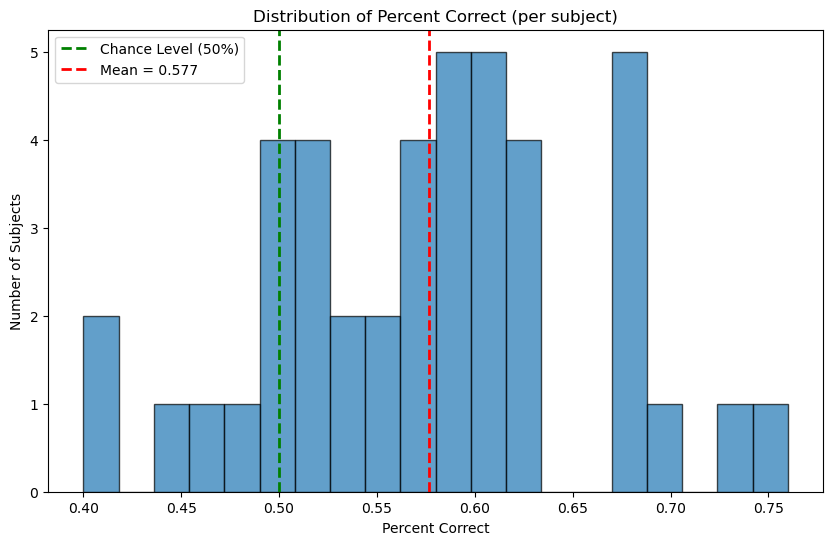

In [10]:
# unified plot
plt.figure(figsize=(10, 6))
plt.hist(percent_cor_IDs['cor_ans'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0.5, color='green', linestyle='dashed', linewidth=2, label='Chance Level (50%)')
plt.axvline(percent_cor_IDs['cor_ans'].mean(), color='red', 
            linestyle='dashed', linewidth=2, label=f'Mean = {percent_cor_IDs["cor_ans"].mean():.3f}')
plt.xlabel("Percent Correct")
plt.ylabel("Number of Subjects")
plt.title("Distribution of Percent Correct (per subject)")
plt.legend()
plt.show()

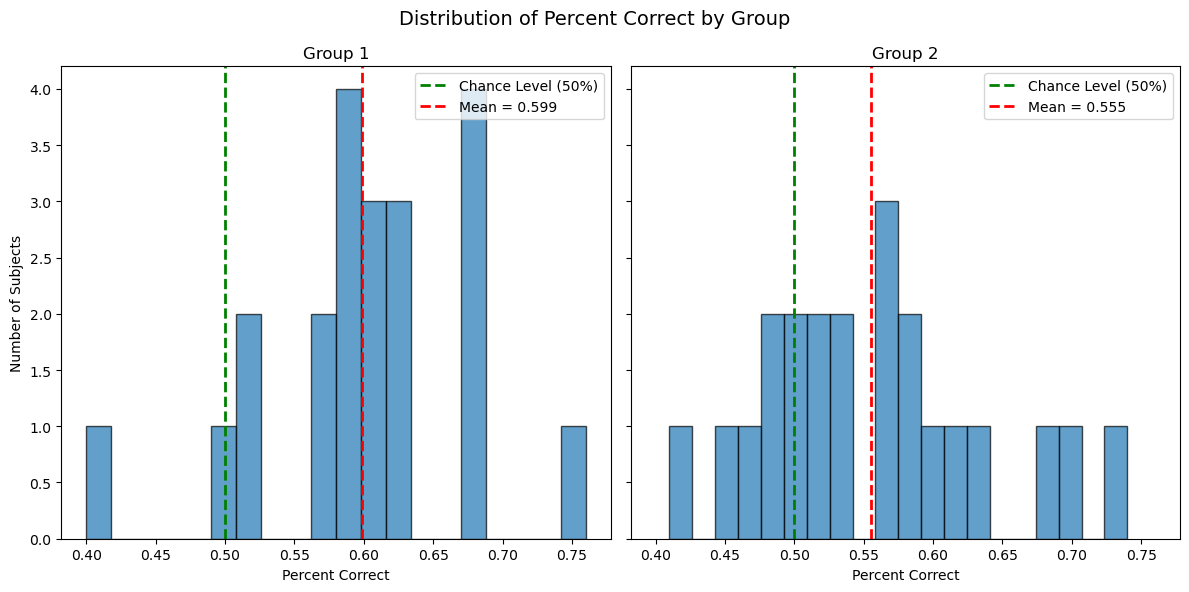

In [11]:
# by groups
groups = np.sort(percent_cor_IDs["group"].unique())
fig, axes = plt.subplots(1, len(groups), # rows, cols
                         figsize=(12, 6), 
                         sharey=True,sharex=True # share x and y axis scales
                         )

for ax, g in zip(axes, groups):
    data = percent_cor_IDs.loc[percent_cor_IDs["group"] == g, "cor_ans"]
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(.50, color="green", linestyle="dashed", linewidth=2, label="Chance Level (50%)")
    # Group mean
    ax.axvline(data.mean(), color="red", linestyle="dashed", linewidth=2, label=f"Mean = {data.mean():.3f}")
    
    ax.set_title(f"Group {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    ax.set_xlabel("Percent Correct")
    ax.legend()

axes[0].set_ylabel("Number of Subjects")
fig.suptitle("Distribution of Percent Correct by Group", fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
# Comment this chunk for now









# # Get unique subject IDs from data
# all_IDs = filtered_data_test['subject_id'].unique()

# # Compute difference
# not_credited_yet = [id for id in all_IDs if id not in credited_IDs]

# print(not_credited_yet)

88970, 89344

In [13]:
# len(not_credited_yet) # Number of subjects not credited yet

In [14]:
credited_IDs = data_test['subject_id'].unique()

In [15]:
credited_IDs

[90163, 90293, 90221, 89118, 88926, ..., 90235, 88788, 86883, 86329, 88914]
Length: 43
Categories (43, int64): [86329, 86400, 86706, 86725, ..., 90221, 90235, 90261, 90293]

87768

In [16]:
# IDs who completed the experiment more than once
ID_trial_count = data_test['subject_id'].value_counts()
(ID_trial_count
 .index[ np.where( ID_trial_count.values > 100 ) ] # IDs with more than 100 trials
 .tolist() # more readable format
 )

[]

# d' by ID

Calculate d' with adjustments (for both hits and false alarms Macmillan & Kaplan, 1985), so that if there is a perfect (1) or terrible (0) hit, or fa, we still got a value (not infinity):
$$\text{Hit} = \frac{N_{hits} + 0.5}{N_{signal\_trials} + 1}$$

Same for FAs.

In [17]:
# Compute hits and number of signal trials per subject
hits_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Target']
    .groupby('subject_id', observed=True)
    .agg(
        hits=('cor_ans', 'sum'),
        signal_trials=('cor_ans', 'count')
    )
    .reset_index()
)

# Compute unadjusted hit rate
hits_IDs['Hit_rate'] = hits_IDs['hits'] / hits_IDs['signal_trials']

# Apply Macmillan & Kaplan (1985) correction
hits_IDs['Hit_rate_adj'] = (hits_IDs['hits'] + 0.5) / (hits_IDs['signal_trials'] + 1)
hits_IDs

,subject_id,hits,signal_trials,Hit_rate,Hit_rate_adj
0,86329,32,50,0.64,0.637255
1,86400,39,50,0.78,0.774510
2,86706,38,50,0.76,0.754902
3,86725,34,50,0.68,0.676471
4,86880,36,50,0.72,0.715686
5,86883,28,50,0.56,0.558824
6,86923,36,50,0.72,0.715686
7,86965,41,50,0.82,0.813725
8,87016,33,50,0.66,0.656863
9,87490,37,50,0.74,0.735294


In [18]:
# Compute false alarms and number of noise trials per subject
FA_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Foil']
    .groupby('subject_id', observed=True)
    .agg(
        # Count "l" responses as false alarms
        FA=('response', lambda x: (x == 'l').sum()),
        noise_trials=('response', 'count')
    )
    .reset_index()
)

# Compute unadjusted false alarm rate
FA_IDs['FA_rate'] = FA_IDs['FA'] / FA_IDs['noise_trials']

# Apply Macmillan & Kaplan (1985) correction
FA_IDs['FA_rate_adj'] = (FA_IDs['FA'] + 0.5) / (FA_IDs['noise_trials'] + 1)

FA_IDs

,subject_id,FA,noise_trials,FA_rate,FA_rate_adj
0,86329,31,50,0.62,0.617647
1,86400,30,50,0.60,0.598039
2,86706,20,50,0.40,0.401961
3,86725,32,50,0.64,0.637255
4,86880,10,50,0.20,0.205882
5,86883,33,50,0.66,0.656863
6,86923,28,50,0.56,0.558824
7,86965,32,50,0.64,0.637255
8,87016,35,50,0.70,0.696078
9,87490,19,50,0.38,0.382353


In [19]:
# Calculate d'
dprime_ID = pd.merge(hits_IDs, FA_IDs, on='subject_id')
dprime_ID['dprimes'] = [stats.norm.ppf(hit) - stats.norm.ppf( (fa) ) 
  for hit, fa 
  in zip(dprime_ID['Hit_rate_adj'], dprime_ID['FA_rate_adj'])
  ]

# Drop columns
dprime_ID = (dprime_ID
 .drop( columns={'hits', 'signal_trials', 'Hit_rate', 'FA', 'noise_trials', 'FA_rate'})
 .rename(columns = {'Hit_rate_adj':'Hit_rate',
                    'FA_rate_adj':'FA_rate'})
 )

dprime_ID

,subject_id,Hit_rate,FA_rate,dprimes
0,86329,0.637255,0.617647,0.051824
1,86400,0.774510,0.598039,0.505506
2,86706,0.754902,0.401961,0.938272
3,86725,0.676471,0.637255,0.106721
4,86880,0.715686,0.205882,1.390866
5,86883,0.558824,0.656863,-0.255929
6,86923,0.715686,0.558824,0.422087
7,86965,0.813725,0.637255,0.540578
8,87016,0.656863,0.696078,-0.109239
9,87490,0.735294,0.382353,0.928211


In [20]:
# # add groups from percent_cor_IDs
# dprime_ID = pd.merge(
#     dprime_ID, 
#     percent_cor_IDs[['subject_id','group']], 
#     on='subject_id'
#     )
# dprime_ID

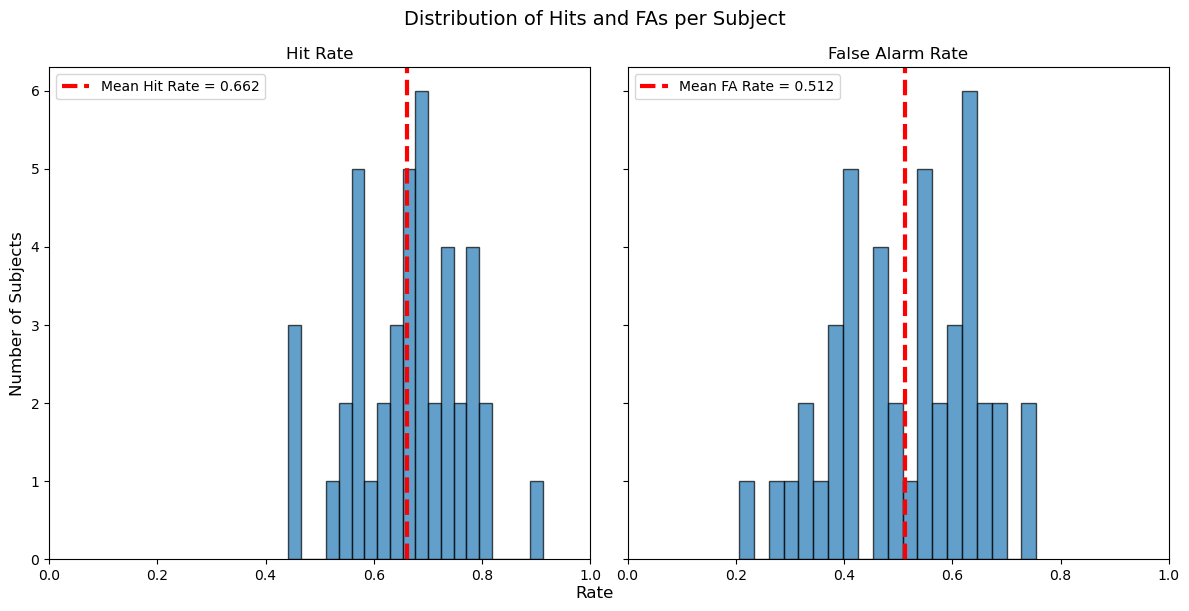

In [21]:
fig, axes = plt.subplots(1, 2, # rows, cols
                         figsize=(12, 6), 
                         sharey=True,sharex=True # share x and y axis scales
                         )


axes[0].hist(dprime_ID['Hit_rate'], bins=20, edgecolor="black", alpha=0.7)
axes[1].hist(dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)

axes[0].set_xlim(0, 1)

# Mean
axes[0].axvline(dprime_ID['Hit_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean Hit Rate = {dprime_ID['Hit_rate'].mean():.3f}")
axes[1].axvline(dprime_ID['FA_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean FA Rate = {dprime_ID['FA_rate'].mean():.3f}")

axes[0].set_title("Hit Rate")
axes[1].set_title("False Alarm Rate") 

fig.text(0.5, 0, "Rate", ha="center", fontsize=12)

axes[0].legend()
axes[1].legend()

axes[0].set_ylabel("Number of Subjects", fontsize=12)
fig.suptitle("Distribution of Hits and FAs per Subject", fontsize=14)
plt.tight_layout()
plt.show()

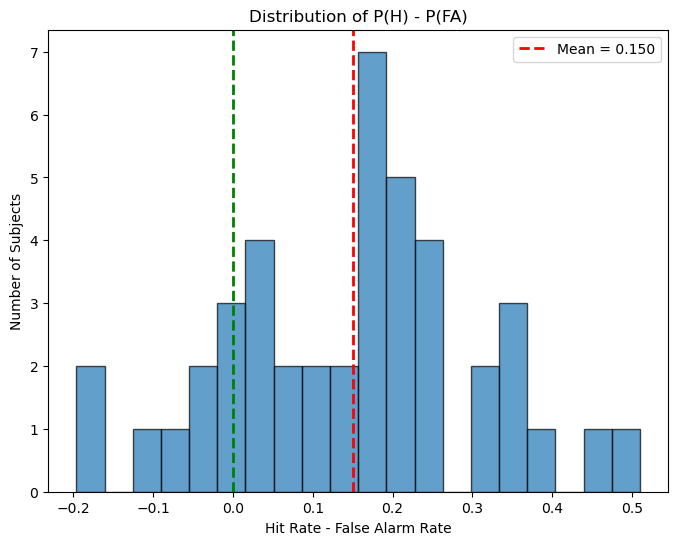

In [22]:
# p(H) - p(FA) plot
plt.figure(figsize=(8, 6))
plt.hist(dprime_ID['Hit_rate'] - dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0, color='green', linestyle='dashed', linewidth=2)
plt.axvline((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']).mean(), 
            color='red', linestyle='dashed', linewidth=2,
            label=f'Mean = {(dprime_ID["Hit_rate"] - dprime_ID["FA_rate"]).mean():.3f}')
plt.xlabel("Hit Rate - False Alarm Rate")
plt.ylabel("Number of Subjects")
plt.title("Distribution of P(H) - P(FA)")
plt.legend()
plt.show()

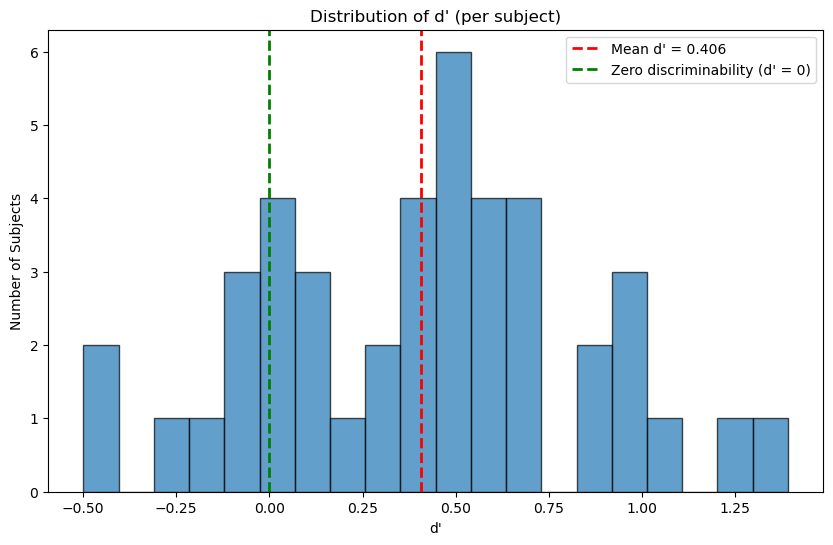

In [23]:
# d'
plt.figure(figsize=(10, 6))
plt.hist(dprime_ID['dprimes'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(np.mean(dprime_ID['dprimes']), color='red', linestyle='dashed', linewidth=2, label=f'Mean d\' = {np.mean(dprime_ID["dprimes"]):.3f}')
plt.axvline(0, color='green', linestyle='dashed', linewidth=2, label="Zero discriminability (d' = 0)")
plt.xlabel("d'")
plt.ylabel("Number of Subjects")
plt.title("Distribution of d' (per subject)")
plt.legend()
plt.show()

## Filter by Hit - FA

In [24]:
threshold = (dprime_ID['Hit_rate'] - dprime_ID['FA_rate']).quantile(0.5)

print(f"Threshold for good subjects: {threshold:.3f}")

dprime_ID['good_subj'] = np.where(
    dprime_ID['Hit_rate'] - dprime_ID['FA_rate'] >= threshold, True, False
    )

bad_subjects = dprime_ID.loc[dprime_ID['good_subj'] == False,'subject_id'].tolist()

Threshold for good subjects: 0.176


In [25]:
# Add column good_subj (filter by Hit - FA)
data_test = (pd.merge(data_test, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )
data_memory = (pd.merge(data_memory, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )

In [26]:
# save filtered data
filtered_data_test = data_test[data_test['good_subj'] == True]
filtered_data_memory = data_memory[data_memory['good_subj'] == True]

In [27]:
n_subj = filtered_data_test.groupby('group', observed=True)['subject_id'].nunique() # number of good subjects
print(f'Number of subjects in')
print(f' {n_subj.index[0]}: {n_subj.values[0]} ({n_subj.values[0] / n_subj.values.sum():.2%})')
print(f' {n_subj.index[1]}: {n_subj.values[1]} ({n_subj.values[1] / n_subj.values.sum():.2%})')
print(f'\n Total: {n_subj.values.sum()}')

Number of subjects in
 Group1: 15 (68.18%)
 Group2: 7 (31.82%)

 Total: 22


# d' by item

In [28]:
df_by_item = (filtered_data_test
            .groupby(['image_id','group'], observed=True)
            .agg(n_subj=('cor_ans', 'size'),
                n_yes=('response', lambda x: (x == "l").sum()),
                item_type=('item_type', 'first'),
                category_name=('category_name', 'first'),
                distinct_rating=('distinct_rating', 'first'),
                distinct_type=('distinct_type', 'first') 
                )
            .reset_index()
            .assign(prop_yes=lambda df: (df['n_yes']+0.5) / (df['n_subj']+1), # Apply Macmillan & Kaplan (1985) correction
                    resp_type = lambda df: np.where(df['item_type'] == 'Target', 'Hit', 'FA')
                    )
            )
df_by_item

,image_id,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type
0,3,Group1,15,4,Foil,Andesite,3.17,Bottom,0.28125,FA
1,3,Group2,7,3,Target,Andesite,3.17,Bottom,0.43750,Hit
2,4,Group1,15,6,Foil,Andesite,3.18,Bottom,0.40625,FA
3,4,Group2,7,3,Target,Andesite,3.18,Bottom,0.43750,Hit
4,6,Group1,15,14,Target,Andesite,3.17,Bottom,0.90625,Hit
...,...,...,...,...,...,...,...,...,...,...
195,471,Group2,7,4,Target,Shale,2.73,Bottom,0.56250,Hit
196,472,Group1,15,12,Target,Shale,2.55,Bottom,0.78125,Hit
197,472,Group2,7,2,Foil,Shale,2.55,Bottom,0.31250,FA
198,476,Group1,15,12,Target,Shale,2.48,Bottom,0.78125,Hit


In [29]:
df_by_item_wide = df_by_item.pivot(index="image_id", columns="resp_type", values="prop_yes")
df_by_item_wide

resp_type,FA,Hit
image_id,,
3,0.28125,0.43750
4,0.40625,0.43750
6,0.31250,0.90625
8,0.56250,0.78125
9,0.65625,0.81250
...,...,...
466,0.34375,0.56250
467,0.59375,0.81250
471,0.46875,0.56250


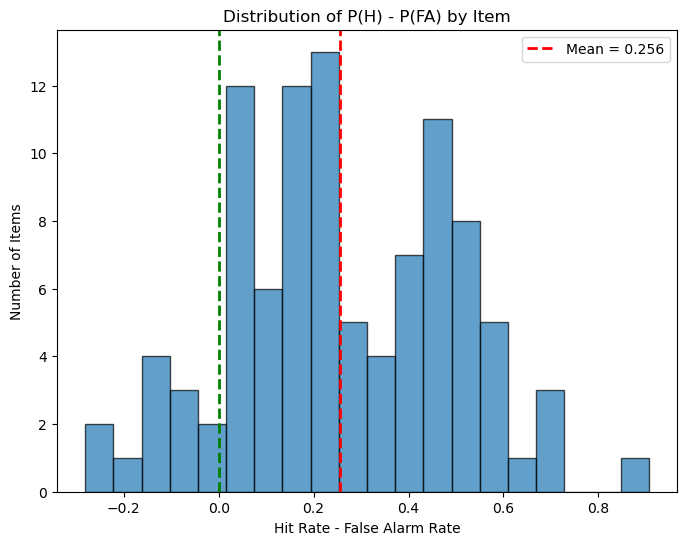

In [30]:
# p(H) - p(FA) plot by item
# df_by_item_wide = df_by_item.pivot(index="image_id", columns="resp_type", values="prop_yes")

plt.figure(figsize=(8, 6))
plt.hist(df_by_item_wide['Hit'] - df_by_item_wide['FA'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0, color='green', linestyle='dashed', linewidth=2)
plt.axvline((df_by_item_wide['Hit'] - df_by_item_wide['FA']).mean(), 
            color='red', linestyle='dashed', linewidth=2,
            label=f'Mean = {(df_by_item_wide["Hit"] - df_by_item_wide["FA"]).mean():.3f}')
plt.xlabel("Hit Rate - False Alarm Rate")
plt.ylabel("Number of Items")
plt.title("Distribution of P(H) - P(FA) by Item")
plt.legend()
plt.show()

In [31]:
# convert resp_type to categorical
df_by_item['resp_type'] = df_by_item['resp_type'].astype('category')
df_by_item['distinct_type'] = df_by_item['distinct_type'].astype('category')

In [32]:
# Simple linear regression: Y ~ X
m1 = smf.ols(
    "prop_yes ~ C(distinct_type) * C(resp_type)", # C() guarantees categorical treatment
    data=df_by_item
    ).fit()

(round(
    anova_lm(m1, typ = 2, robust = 'hc3'),
    4)
 )

,sum_sq,df,F,PR(>F)
C(distinct_type),2.7604,1.0,90.0528,0.0
C(resp_type),5.8713,1.0,191.5416,0.0
C(distinct_type):C(resp_type),1.7635,1.0,57.5321,0.0
Residual,6.0080,196.0,NaN,NaN


In [33]:
# # Test H0: slope_Hit = 0
# m1.t_test("distinct_rating + distinct_rating:resp_type[T.Hit] = 0")

In [34]:
# Post-hoc
def run_posthoc_contrasts(
    group_means,
    group_vars,
    n,
    contrasts,
    mse=None,
    alpha=0.05,
    levene_alpha=0.05,
    raw_groups=None,  # dict or list of per-group raw arrays, needed for Levene's test
):
    if raw_groups is None:
        raise ValueError(
            "`raw_groups` must be provided (list of per-group raw arrays) to run Levene's test."
        )

    # ── Levene's test ──────────────────────────────────────────────────────────
    levene_stat, levene_p = stats.levene(*raw_groups)
    account_for_variance = levene_p < levene_alpha

    print(f"Levene's test:  W = {levene_stat:.3f},  p = {levene_p:.3f}")
    if account_for_variance:
        print(
            f"  → Variances differ significantly (p < {levene_alpha}). "
            "Running Welch-Satterthwaite contrasts (heterogeneous variances).\n"
        )
    else:
        if mse is None:
            raise ValueError(
                "Levene's test is non-significant (homogeneous variances assumed), "
                "but `mse` was not provided. Pass the ANOVA residual MSE to use pooled SE."
            )
        print(
            f"  → Variances are homogeneous (p ≥ {levene_alpha}). "
            "Running pooled-MSE contrasts.\n"
        )

    # ── Contrasts ──────────────────────────────────────────────────────────────
    results = {}
    n_comparisons = len(contrasts)

    for name, weights in contrasts.items():
        w = np.array(weights)
        estimate = w @ group_means

        if account_for_variance:
            var_terms = (w ** 2) * (group_vars / n)
            se = np.sqrt(var_terms.sum())
            df = var_terms.sum() ** 2 / ((var_terms ** 2) / (n - 1)).sum()
        else:
            se = np.sqrt(mse * (w ** 2 / n).sum())
            df = None  # report ANOVA residual df externally

        t_stat = estimate / se
        p_value = 2 * stats.t.sf(np.abs(t_stat), df=df)
        p_adjusted = min(p_value * n_comparisons, 1.0)

        thresholds = [0.001, 0.01, alpha]
        stars = ["***", "**", "*"]
        sig = next((s for s, thr in zip(stars, thresholds) if p_adjusted < thr), "")

        results[name] = {
            "estimate": estimate,
            "t_stat": t_stat,
            "df": df,
            "p_value": p_value,
            "p_adjusted": p_adjusted,
            "significance": sig,
        }

    out = pd.DataFrame(results).T
    num_cols = ["estimate", "t_stat", "df", "p_value", "p_adjusted"]
    out[num_cols] = out[num_cols].astype(float).round(3)
    return out

In [35]:
anova_table = anova_lm(m1, typ = 2)
mse = anova_table['sum_sq']['Residual'] / anova_table['df']['Residual']

# Get group means
group_means = df_by_item.groupby(['distinct_type','resp_type'], observed=True)['prop_yes'].mean()
group_vars = df_by_item.groupby(['distinct_type','resp_type'], observed=True)['prop_yes'].var() # need to account for different variances across groups
n = df_by_item.groupby(['distinct_type','resp_type'], observed=True).size() # Sample sizes

# Manually specify contrasts based on the means and MSE from the ANOVA
contrasts = {
    # ========== Hits ==========
    'Low vs high hits': (0, 1, 0, -1),
    # ========== FAs ==========
    'Low vs high FAs': (1, 0, -1, 0),
}

raw_groups = [
    df_by_item.loc[df_by_item.groupby(['distinct_type','resp_type'], observed=True).groups[key], 'prop_yes'].values
    for key in group_means.index
]

posthoc = run_posthoc_contrasts(
    group_means=group_means,
    group_vars=group_vars,
    n=n,
    contrasts=contrasts,
    mse=mse,           # still pass it — used only if Levene's is non-significant
    raw_groups=raw_groups,
)
posthoc

Levene's test:  W = 9.126,  p = 0.000
  → Variances differ significantly (p < 0.05). Running Welch-Satterthwaite contrasts (heterogeneous variances).



,estimate,t_stat,df,p_value,p_adjusted,significance
Low vs high hits,0.008,0.211,24.153,0.834,1.0,
Low vs high FAs,0.382,12.371,56.503,0.000,0.0,***


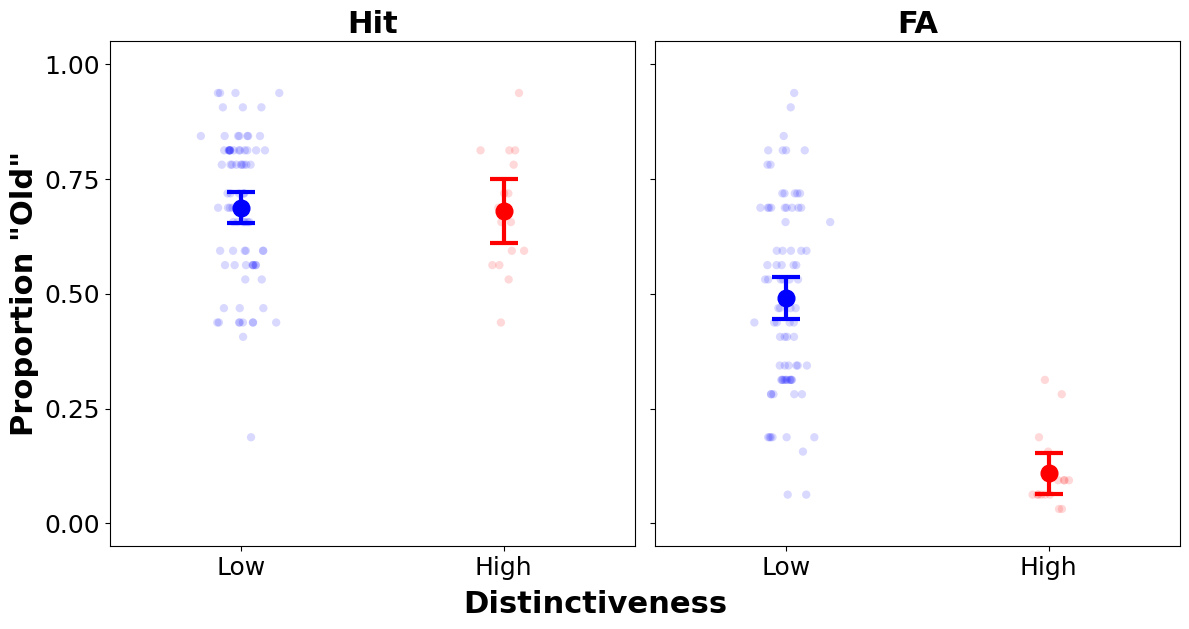

In [36]:
# Summary statistics
summary = (
    df_by_item
    .groupby(["resp_type", "distinct_type"], observed=False)
    .agg(
        mean_prop=("prop_yes", "mean"),
        n=("prop_yes", "size"),
        sd=("prop_yes", "std")
    )
    .reset_index()
)
summary["se"] = summary["sd"] / np.sqrt(summary["n"])
summary["ci95"] = summary["se"] * stats.t.ppf(0.975, summary["n"] - 1)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
resp_levels = ["Hit", "FA"]
x_levels = sorted(df_by_item["distinct_type"].unique()) # levels [Bottom, Top]
x_pos = np.arange(len(x_levels)) # create numerical x positions

# Define color map
color_map = {
    "Bottom": "blue",
    "Top": "red"
}
x_label_map = {
    "Bottom": "Low",
    "Top": "High"
}

# for Hits and FAs
for ax, resp in zip(axes, resp_levels):
    
    # Raw data (jittered)
    raw = df_by_item[df_by_item["resp_type"] == resp]
    
    # For each distinctiveness level
    for i, level in enumerate(x_levels):
        y = raw.loc[raw["distinct_type"] == level, "prop_yes"]
        x = np.random.normal(i, 0.05, size=len(y))  # jitter
        
        ax.scatter(
            x, y,
            alpha=0.15,
            edgecolor="none",
            color=color_map[level]
        )
    
    # Summary stats
    summ = summary[summary["resp_type"] == resp]
    for idx, row in summ.iterrows():
        lvl = row["distinct_type"]
        # Find the x-position for this distinctiveness level
        x_idx = x_levels.index(lvl)
        
        ax.errorbar(
            x_idx,  # Use x-position, not pandas index
            row["mean_prop"],
            yerr=row["ci95"],
            fmt="o",
            capsize=10,
            capthick=3,
            linewidth=3,
            markersize=12,
            color=color_map[lvl]
        )
    
    ax.set_title(resp, fontsize=22, fontweight="bold")

fs = 22
fs_axes = 18
axes[0].set_ylabel('Proportion "Old"', fontsize=fs, fontweight="bold")
fig.text(0.5, -0.03, "Distinctiveness", ha="center",
         fontsize=fs, fontweight="bold")

for ax in axes:
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_levels, fontsize=fs_axes)
    ax.set_xlim(-0.5, len(x_levels) - 0.5)
    ax.set_xticklabels(
        [x_label_map[lvl] for lvl in x_levels],
        fontsize=fs_axes
    )
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.25))
    ax.tick_params(axis="both", labelsize=fs_axes)

plt.tight_layout()
plt.show()

# Split-Half

In [37]:
# add response types to filtered_data_test
conditions = [
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == False),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == False),
]

choices = ['Hit', 'Miss', 'CR', 'FA']

filtered_data_test['resp_type'] = np.select(conditions, choices, default=None)
filtered_data_test

,trial_index,subject_id,group,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,good_subj,resp_type
0,107,90163,Group2,test_phase,Target,l,l,True,1986.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom,True,Hit
1,109,90163,Group2,test_phase,Foil,a,a,True,1453.0,Gneiss,13,M,M_Gneiss_06.png,198,2.65,Bottom,True,CR
2,111,90163,Group2,test_phase,Target,l,l,True,1956.0,Marble,15,M,M_Marble_14.png,238,3.31,Bottom,True,Hit
3,113,90163,Group2,test_phase,Target,l,l,True,1035.0,Phyllite,17,M,M_Phyllite_13.png,269,2.80,Bottom,True,Hit
4,115,90163,Group2,test_phase,Target,l,l,True,1156.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4295,297,88914,Group1,test_phase,Target,a,l,False,760.0,Basalt,2,I,I_Basalt_01.png,17,1.92,Bottom,True,Miss
4296,299,88914,Group1,test_phase,Target,l,l,True,1985.0,Diorite,3,I,I_Diorite_05.png,37,3.08,Bottom,True,Hit
4297,301,88914,Group1,test_phase,Foil,l,a,False,1573.0,Andesite,1,I,I_Andesite_09.png,9,2.49,Bottom,True,FA
4298,303,88914,Group1,test_phase,Target,l,l,True,552.0,Diorite,3,I,I_Diorite_04.png,36,2.98,Bottom,True,Hit


In [38]:
# ---------- Hits data for split-half reliability analysis ----------

# ---------- Group 1 ----------

sh_df_hits_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_gr1_long['is_hit'] = np.where(sh_df_hits_gr1_long['resp_type']=='Hit', 1, 0)  # is hit or miss
sh_df_hits_gr1_long = sh_df_hits_gr1_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_gr1 = sh_df_hits_gr1_long.pivot(index='image_id', columns='subject_id', values='is_hit')


# ---------- Group 2 ----------

sh_df_hits_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_gr2_long['is_hit'] = np.where(sh_df_hits_gr2_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_gr2_long = sh_df_hits_gr2_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_gr2 = sh_df_hits_gr2_long.pivot(index='image_id', columns='subject_id', values='is_hit')

In [39]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for hit, 0 for miss
sh_df_hits_gr2.head(10)

subject_id,90163,90221,88805,86965,89804,88931,88788
image_id,,,,,,,
3,0,0,0,1,1,0,1
4,1,0,0,1,0,0,1
9,1,1,1,1,1,0,1
24,0,1,1,1,0,1,1
26,0,0,0,1,0,1,1
29,0,1,1,1,1,0,1
33,1,0,1,1,0,1,1
42,1,1,1,0,1,1,1
47,1,0,1,1,1,1,1


In [40]:
# ---------- FA data for split-half reliability analysis ----------

# ---------- Group 1 ----------

sh_df_fa_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_gr1_long['is_fa'] = np.where(sh_df_fa_gr1_long['resp_type']=='FA', 1, 0)  # is fa or cr
sh_df_fa_gr1_long = sh_df_fa_gr1_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_gr1 = sh_df_fa_gr1_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- Group 2 ----------

sh_df_fa_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_gr2_long['is_fa'] = np.where(sh_df_fa_gr2_long['resp_type']=='FA', 1, 0)  
sh_df_fa_gr2_long = sh_df_fa_gr2_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_gr2 = sh_df_fa_gr2_long.pivot(index='image_id', columns='subject_id', values='is_fa')

In [41]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for FA, 0 for CR
sh_df_fa_gr2.head(10)

subject_id,90163,90221,88805,86965,89804,88931,88788
image_id,,,,,,,
6,0,0,0,1,0,1,0
8,1,1,0,1,1,0,0
10,0,0,0,1,0,0,0
17,1,1,1,1,0,1,1
18,1,1,1,1,1,0,0
25,1,1,1,1,1,0,0
35,1,1,1,1,0,1,1
36,1,1,1,1,0,1,1
37,1,0,1,1,1,1,1


In [42]:
# Store everything together
split_half_hits_dict = {
    "Group1": sh_df_hits_gr1,
    "Group2": sh_df_hits_gr2
}

split_half_fa_dict = {
    "Group1": sh_df_fa_gr1,
    "Group2": sh_df_fa_gr2
}

In [43]:
# function to compute split-half reliability

def split_half_reliability(df_gr1, df_gr2, n_iterations=10000, seed=1, is_random=False, print_idx=1000):
    
    np.random.seed(seed)
    corrs = []
    print('Iteration: ', end="")
    
    for i in range(n_iterations):
        
        if i % print_idx == 0:
            print(i, end=", ")
        elif i == n_iterations - 1:
            print("Finished!")
        
        # ----- Group 1 -----
        shuffled_cols_1 = np.random.permutation(df_gr1.columns)
        shuffled_df_1 = df_gr1[shuffled_cols_1]
        
        mid_1 = len(shuffled_df_1.columns) // 2
        first_half_1 = shuffled_df_1.iloc[:, :mid_1]
        second_half_1 = shuffled_df_1.iloc[:, mid_1:]
        
        mean_first_1 = first_half_1.mean(axis=1)
        mean_second_1 = second_half_1.mean(axis=1)
        
        # ----- Group 2 -----
        shuffled_cols_2 = np.random.permutation(df_gr2.columns)
        shuffled_df_2 = df_gr2[shuffled_cols_2]
        
        mid_2 = len(shuffled_df_2.columns) // 2
        first_half_2 = shuffled_df_2.iloc[:, :mid_2]
        second_half_2 = shuffled_df_2.iloc[:, mid_2:]
        
        mean_first_2 = first_half_2.mean(axis=1)
        mean_second_2 = second_half_2.mean(axis=1)
        
        # ----- Combine -----
        mean_first = pd.concat([mean_first_1, mean_first_2])
        mean_second = pd.concat([mean_second_1, mean_second_2])
        
        if is_random:
            # Shuffle the second half to get a null distribution
            mean_second = np.random.permutation(mean_second.values)
        
        # Spearman correlation + Spearman-Brown correction
        r, _ = stats.spearmanr(mean_first, mean_second)
        sb = (2 * r) / (1 + r)
        
        corrs.append(sb)
        
    return np.array(corrs)

In [44]:
# Run split-half reliability analysis
sh_corrs_hits = {'Exact': None, 'Random': None}
sh_corrs_fa = {'Exact': None, 'Random': None}
N_iter = 10**4

df_gr1 = split_half_hits_dict["Group1"]
df_gr2 = split_half_hits_dict["Group2"]

print("\nRunning Hits split-half - Exact")
sh_corrs_hits['Exact'] = split_half_reliability(df_gr1, df_gr2,
                                                 n_iterations=N_iter, seed=12345, is_random=False)

print("\nRunning Hits split-half - Random")
sh_corrs_hits['Random'] = split_half_reliability(df_gr1, df_gr2,
                                                  n_iterations=N_iter, seed=12345, is_random=True)

df_gr1 = split_half_fa_dict["Group1"]
df_gr2 = split_half_fa_dict["Group2"]

print("\nRunning FA split-half - Exact")
sh_corrs_fa['Exact'] = split_half_reliability(df_gr1, df_gr2,
                                               n_iterations=N_iter, seed=12345, is_random=False)

print("\nRunning FA split-half - Random")
sh_corrs_fa['Random'] = split_half_reliability(df_gr1, df_gr2,
                                                n_iterations=N_iter, seed=12345, is_random=True)


Running Hits split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!


## Plots SH

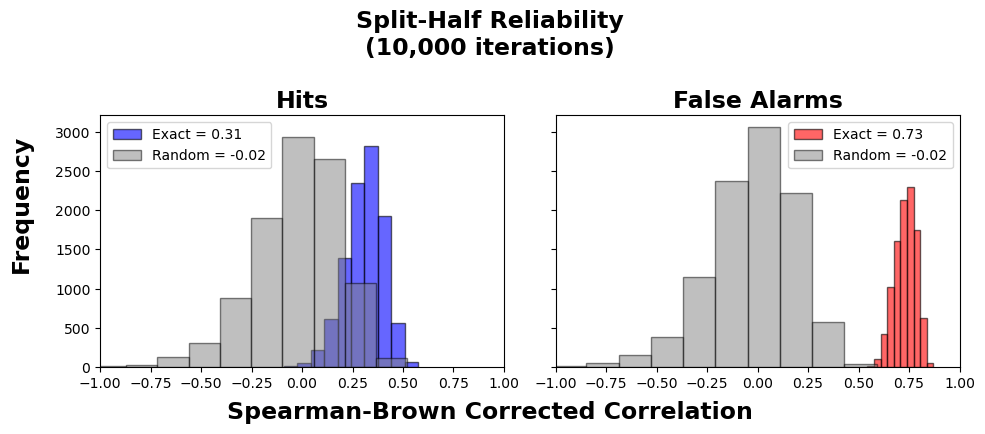

In [45]:
# Visualize split-half reliability results

n_bins = 10
fs_title = 17
fs_ax_labels = 17
fs_grid_labels = 17

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

# ----- Hits -----
axes[0].hist(
    sh_corrs_hits['Exact'],
    color='blue', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_hits["Exact"]):.2f}'
)

axes[0].hist(
    sh_corrs_hits['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_hits["Random"]):.2f}'
)

axes[0].set_title('Hits', fontsize=fs_grid_labels, fontweight='bold')
axes[0].legend()

# ----- FA -----
axes[1].hist(
    sh_corrs_fa['Exact'],
    color='red', alpha=0.6, edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_fa["Exact"]):.2f}'
)

axes[1].hist(
    sh_corrs_fa['Random'],
    color='gray', alpha=0.5, edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_fa["Random"]):.2f}'
)

axes[1].set_title('False Alarms', fontsize=fs_grid_labels, fontweight='bold')
axes[1].legend()

# Global labels
for ax in axes.flatten():
    ax.set_xlim(-1, 1)

fig.text(0.5, 0.02, 'Spearman-Brown Corrected Correlation', ha='center', fontsize=fs_ax_labels, fontweight='bold')
fig.text(0.02, 0.5, 'Frequency', va='center', rotation='vertical', fontsize=fs_ax_labels, fontweight='bold')

plt.suptitle("Split-Half Reliability\n(10,000 iterations)",
              ha='center', y=0.93, fontsize=fs_title, fontweight='bold')
plt.tight_layout(rect=[0.05, 0.05, 1, 0.93])
plt.show()

# Hit vs FA Correlations by Distinctiveness

In [46]:
# wider format with Hit and FA columns
df_by_item_wide = (df_by_item[['image_id','category_name',
                                'distinct_rating','prop_yes',
                                'resp_type', 'distinct_type']]
                    .pivot(index = ['image_id', 'category_name', 'distinct_rating', 'distinct_type'], 
                            columns='resp_type', values='prop_yes')
                    .reset_index()
                    )
df_by_item_wide

resp_type,image_id,category_name,distinct_rating,distinct_type,FA,Hit
0,3,Andesite,3.17,Bottom,0.28125,0.43750
1,4,Andesite,3.18,Bottom,0.40625,0.43750
2,6,Andesite,3.17,Bottom,0.31250,0.90625
3,8,Andesite,1.95,Bottom,0.56250,0.78125
4,9,Andesite,2.49,Bottom,0.65625,0.81250
...,...,...,...,...,...,...
95,466,Shale,2.90,Bottom,0.34375,0.56250
96,467,Shale,1.95,Bottom,0.59375,0.81250
97,471,Shale,2.73,Bottom,0.46875,0.56250
98,472,Shale,2.55,Bottom,0.31250,0.78125


In [47]:
# Convert categorical to string, then create composite column
df_by_item['resp_group'] = df_by_item['resp_type'].astype(str) + '_' + df_by_item['group'].astype(str)

# Then pivot using this new column, including distinct_group in the index
df_by_item_wide = (df_by_item[['image_id', 'category_name', 
                                'distinct_rating', 'distinct_type',
                                'prop_yes', 'resp_group']]
                    .pivot(index=['image_id', 'category_name', 'distinct_rating', 'distinct_type'], 
                           columns='resp_group', 
                           values='prop_yes')
                    .reset_index()
                    )

df_by_item_wide

resp_group,image_id,category_name,distinct_rating,distinct_type,FA_Group1,FA_Group2,Hit_Group1,Hit_Group2
0,3,Andesite,3.17,Bottom,0.28125,NaN,NaN,0.4375
1,4,Andesite,3.18,Bottom,0.40625,NaN,NaN,0.4375
2,6,Andesite,3.17,Bottom,NaN,0.3125,0.90625,NaN
3,8,Andesite,1.95,Bottom,NaN,0.5625,0.78125,NaN
4,9,Andesite,2.49,Bottom,0.65625,NaN,NaN,0.8125
...,...,...,...,...,...,...,...,...
95,466,Shale,2.90,Bottom,0.34375,NaN,NaN,0.5625
96,467,Shale,1.95,Bottom,0.59375,NaN,NaN,0.8125
97,471,Shale,2.73,Bottom,0.46875,NaN,NaN,0.5625
98,472,Shale,2.55,Bottom,NaN,0.3125,0.78125,NaN


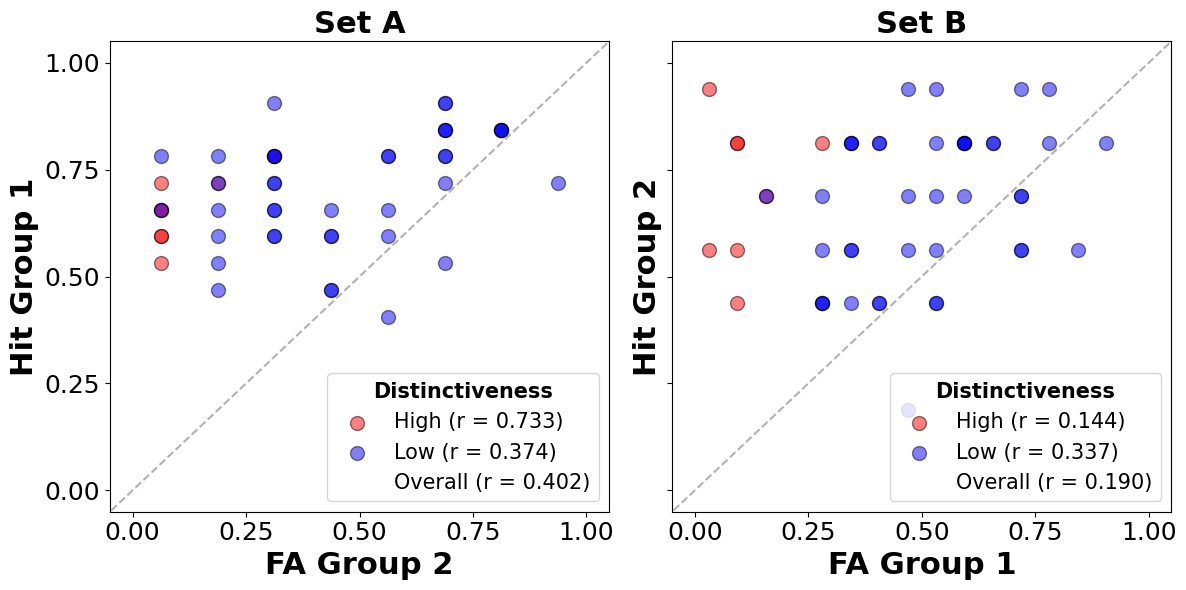

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, sharex=True)
axes = axes.ravel()

distinct_groups = {'Top': 'High', 'Bottom': 'Low'}
colors = ['red', 'blue']

# For overall correlations
x_all_0, y_all_0 = [], []
x_all_1, y_all_1 = [], []

for color, distinct in zip(colors, distinct_groups):
    
    # Distinct name
    dist_name = distinct_groups[distinct]

    # ---------- Left subplot (Set A): FA Group 2, Hit Group 1 ----------
    x = df_by_item.loc[
        (df_by_item['distinct_type'] == distinct) &
        (df_by_item['group'] == 'Group2') &
        (df_by_item['resp_type'] == 'FA'),
        'prop_yes'
    ].reset_index(drop=True)

    y = df_by_item.loc[
        (df_by_item['distinct_type'] == distinct) &
        (df_by_item['group'] == 'Group1') &
        (df_by_item['resp_type'] == 'Hit'),
        'prop_yes'
    ].reset_index(drop=True)

    mask = ~(x.isna() | y.isna())
    r = x[mask].corr(y[mask])

    axes[0].scatter(
        x, y, alpha=0.5, edgecolor="k", color=color, s=100,
        label=f"{dist_name} (r = {r:.3f})"
    )

    # ---------- Right subplot (Set B): FA Group 1, Hit Group 2 ----------
    x_rev = df_by_item.loc[
        (df_by_item['distinct_type'] == distinct) &
        (df_by_item['group'] == 'Group1') &
        (df_by_item['resp_type'] == 'FA'),
        'prop_yes'
    ].reset_index(drop=True)

    y_rev = df_by_item.loc[
        (df_by_item['distinct_type'] == distinct) &
        (df_by_item['group'] == 'Group2') &
        (df_by_item['resp_type'] == 'Hit'),
        'prop_yes'
    ].reset_index(drop=True)

    mask_rev = ~(x_rev.isna() | y_rev.isna())
    r_rev = x_rev[mask_rev].corr(y_rev[mask_rev])

    axes[1].scatter(
        x_rev, y_rev, alpha=0.5, edgecolor="k", color=color, s=100,
        label=f"{dist_name} (r = {r_rev:.3f})"
    )

    # accumulate for overall correlations
    x_all_0.append(x)
    y_all_0.append(y)
    x_all_1.append(x_rev)
    y_all_1.append(y_rev)

# ---------- Overall correlations ----------
x0 = pd.concat(x_all_0, ignore_index=True)
y0 = pd.concat(y_all_0, ignore_index=True)
x1 = pd.concat(x_all_1, ignore_index=True)
y1 = pd.concat(y_all_1, ignore_index=True)

mask0 = ~(x0.isna() | y0.isna())
mask1 = ~(x1.isna() | y1.isna())

r0 = x0[mask0].corr(y0[mask0])
r1 = x1[mask1].corr(y1[mask1])

# ---------- Add dummy legend entries ----------
overall_handle_0 = Line2D([], [], linestyle='None',
                          label=f"Overall (r = {r0:.3f})")
overall_handle_1 = Line2D([], [], linestyle='None',
                          label=f"Overall (r = {r1:.3f})")

# ---------- Formatting ----------
fs = 22 # font size
fs_axes = 18
fs_legend = 15

lims = [-0.05, 1.05]
for ax in axes:
    ax.plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
    ax.set_xlim(lims[0], lims[1])
    ax.set_xticks(np.arange(0, 1.1, 0.25))
    ax.set_ylim(lims[0], lims[1])
    ax.set_yticks(np.arange(0, 1.1, 0.25))
    ax.tick_params(axis='both', labelsize=fs_axes)

axes[0].set_xlabel('FA Group 2', fontweight='bold', fontsize=fs)
axes[0].set_ylabel('Hit Group 1', fontweight='bold', fontsize=fs)
axes[0].set_title('Set A', fontsize=fs, fontweight='bold')

axes[1].set_xlabel('FA Group 1', fontweight='bold', fontsize=fs)
axes[1].set_ylabel('Hit Group 2', fontweight='bold', fontsize=fs)
axes[1].set_title('Set B', fontsize=fs, fontweight='bold')

# rebuild legends with overall r included
handles0, labels0 = axes[0].get_legend_handles_labels()
axes[0].legend(handles0 + [overall_handle_0], 
               labels0 + [overall_handle_0.get_label()],
               title="Distinctiveness", 
               fontsize=fs_legend,
               title_fontsize=fs_legend,
               loc = 'lower right')
axes[0].get_legend().get_title().set_fontweight('bold')

handles1, labels1 = axes[1].get_legend_handles_labels()
axes[1].legend(handles1 + [overall_handle_1], 
               labels1 + [overall_handle_1.get_label()],
               title="Distinctiveness", 
               fontsize=fs_legend,
               title_fontsize=fs_legend,
               loc = 'lower right')
axes[1].get_legend().get_title().set_fontweight('bold')

plt.tight_layout()
plt.show()

In [49]:
# Exact correlations
# (use as a func because later we'll use it for predicted values as well)
def get_H_vs_FA_correlations(df_by_item, pred_col='prop_yes'):

    distinct_groups = ['Top', 'Bottom']
    panels = {
            "Set A (Group2 FA vs Group1 Hit)": ("Group2", "Group1"),
            "Set B (Group1 FA vs Group2 Hit)": ("Group1", "Group2"),
        }

    print(f"Column: {pred_col}")

    for panel_name, (grA, grB) in panels.items():
        print(f"\n{panel_name}")

        x_all, y_all = [], []

        for distinct in distinct_groups:
            x = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == grA) &
                (df_by_item['resp_type'] == 'FA'),
                pred_col
            ].reset_index(drop=True)

            y = df_by_item.loc[
                (df_by_item['distinct_type'] == distinct) &
                (df_by_item['group'] == grB) &
                (df_by_item['resp_type'] == 'Hit'),
                pred_col
            ].reset_index(drop=True)

            mask = ~(x.isna() | y.isna())
            r, p = pearsonr(x[mask], y[mask])

            print(f"  {distinct}: r = {r:.2f}, p = {p:.3f}, n = {mask.sum()}")

            x_all.append(x)
            y_all.append(y)

        # Overall (collapsed over distinctiveness groups)
        x_all = pd.concat(x_all, ignore_index=True)
        y_all = pd.concat(y_all, ignore_index=True)
        mask_all = ~(x_all.isna() | y_all.isna())
        r_all, p_all = pearsonr(x_all[mask_all], y_all[mask_all])

        print(f"  Overall: r = {r_all:.2f}, p = {p_all:.3f}, n = {mask_all.sum()}")

In [50]:
get_H_vs_FA_correlations(df_by_item, pred_col='prop_yes')

Column: prop_yes

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.73, p = 0.038, n = 8
  Bottom: r = 0.37, p = 0.015, n = 42
  Overall: r = 0.40, p = 0.004, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.14, p = 0.734, n = 8
  Bottom: r = 0.34, p = 0.029, n = 42
  Overall: r = 0.19, p = 0.186, n = 50


# Models

## Hybrid-Similarity Model

Hybrid-Similarity Model. 

$$P( 'Old' | i) = P( 'Old' | F_i)$$

Where $P( 'Old' | F_i) = \frac{F_i}{F_i + k}$, where $k$ is a free parameter. 

$F_i = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$ is the similarity between test item $i$ to all study items $j$. 

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D}$ ($c$ is a free parameter, $D = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{- \alpha \times d_i}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

In [51]:
# Load MDS solution
mds_solution = pd.read_csv('https://raw.githubusercontent.com/DaniilAzarov123/Rocks_Database/main/info/Rocks480_MDS8_solution.csv')
mds_solution

,image_id,dim1,dim2,dim3,dim4,dim5,dim6,dim7,dim8
0,1,-2.757,-1.594,1.052,0.768,1.343,1.711,1.795,0.809
1,2,2.001,-0.754,1.405,-1.382,-1.384,0.976,-0.067,1.972
2,3,0.261,-0.508,-2.962,-0.608,0.009,-0.191,2.720,-1.224
3,4,0.382,-0.027,-0.148,-1.899,-1.948,1.862,0.968,0.986
4,5,0.288,2.013,-1.102,-1.285,0.344,-0.009,2.696,-0.174
...,...,...,...,...,...,...,...,...,...
475,476,0.749,-3.021,-1.908,-1.689,-0.493,4.441,-0.122,1.618
476,477,-0.054,-2.743,-1.435,-2.903,0.315,3.161,1.833,1.288
477,478,0.007,-2.077,-4.012,-1.633,-0.366,2.558,4.210,-0.060
478,479,0.177,-2.520,-2.293,-1.216,0.545,0.805,2.302,0.629


In [52]:
# study lists
study_list_gr1 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group1', 'image_id'].unique())
study_list_gr2 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group2', 'image_id'].unique())

# test list
test_list = np.sort(filtered_data_test['image_id'].unique())

In [53]:
# Calculate distances

# Step 1: Extract the MDS coordinates (first 8 columns)
# Make sure image_id is set as the index for easy lookup
mds_coords = mds_solution.set_index('image_id').iloc[:, :8]

# ------------- Group 1 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr1

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr1 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

# ------------- Group 2 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr2

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr2 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

In `dist_mat_gr1` (100x50) and `dist_mat_gr2` (100x50), each row is each test item (they are the **same** accross two matrices), and each column is each study item (they are **different** accross matrices).

In [54]:
# Calculate similarity matrices

def calculate_similarity_matrix(distance_matrix, c):
    # Calculate similarity: exp(-c * d_ij)
    similarity = np.exp(-c * distance_matrix)
    
    # If input is DataFrame, preserve index and columns
    if isinstance(distance_matrix, pd.DataFrame):
        similarity_matrix = pd.DataFrame(
            similarity,
            index=distance_matrix.index,
            columns=distance_matrix.columns
        )
    else:
        similarity_matrix = similarity
    
    return similarity_matrix

In [55]:
# Make a dictionary of distinctiveness (value) by image_id (key)
# [(image_id, distinctiveness), (..., ...)]
distinctiveness_image_id = df_by_item.set_index('image_id')['distinct_rating'].to_dict()
# print first 5 items
list(distinctiveness_image_id.items())[:5]

[(3, 3.17), (4, 3.18), (6, 3.17), (8, 1.95), (9, 2.49)]

In [56]:
# Transform similarities based on distinctiveness
def transform_similarity_matrix(alpha, beta, similarity_matrix, distinctiveness_dict = distinctiveness_image_id):
    # Create a copy to avoid modifying the original
    transformed = similarity_matrix.copy()
    
    # Iterate through each row
    for row_id in transformed.index:
        # Get distinctiveness for this row's image
        distinct_i = distinctiveness_dict[row_id]
        
        # Iterate through each column
        for col_id in transformed.columns:
            s_ij = similarity_matrix.loc[row_id, col_id]
            
            if row_id == col_id:
                # Self-similarity case: exp(beta * distinct_i)
                # Since s_ii = 1
                transformed.loc[row_id, col_id] = np.exp(beta * distinct_i)
            else:
                # Similarity between different items (item i and item j) case
                # s_ij * exp(-alpha * distinct_i)
                transformed.loc[row_id, col_id] = np.exp(-alpha * distinct_i) * s_ij
    
    return transformed

In [57]:
# For NegLogLikelihood calculation
filtered_data_test['responded_old'] = np.where(filtered_data_test['response'] == "l", 1, 0)
filtered_data_test

,trial_index,subject_id,group,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,good_subj,resp_type,responded_old
0,107,90163,Group2,test_phase,Target,l,l,True,1986.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom,True,Hit,1
1,109,90163,Group2,test_phase,Foil,a,a,True,1453.0,Gneiss,13,M,M_Gneiss_06.png,198,2.65,Bottom,True,CR,0
2,111,90163,Group2,test_phase,Target,l,l,True,1956.0,Marble,15,M,M_Marble_14.png,238,3.31,Bottom,True,Hit,1
3,113,90163,Group2,test_phase,Target,l,l,True,1035.0,Phyllite,17,M,M_Phyllite_13.png,269,2.80,Bottom,True,Hit,1
4,115,90163,Group2,test_phase,Target,l,l,True,1156.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,True,Hit,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4295,297,88914,Group1,test_phase,Target,a,l,False,760.0,Basalt,2,I,I_Basalt_01.png,17,1.92,Bottom,True,Miss,0
4296,299,88914,Group1,test_phase,Target,l,l,True,1985.0,Diorite,3,I,I_Diorite_05.png,37,3.08,Bottom,True,Hit,1
4297,301,88914,Group1,test_phase,Foil,l,a,False,1573.0,Andesite,1,I,I_Andesite_09.png,9,2.49,Bottom,True,FA,1
4298,303,88914,Group1,test_phase,Target,l,l,True,552.0,Diorite,3,I,I_Diorite_04.png,36,2.98,Bottom,True,Hit,1


In [58]:
# Different parameters for different groups

def HS_model(parameters,
             data, 
             distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
             distinctiveness_dict = distinctiveness_image_id):
    # parameters
    c, alpha, beta, k = parameters
    
    # get group name
    group = data['group'].unique()[0]
    groupN = 0 if group == 'Group1' else 1
    
    # Distances matrices
    distances_mat = distances_mats_list[groupN]
    
    # (Raw) Similarity matrices
    similarity_mat = np.exp(-c * distances_mat)
    
    # Transform similarities based on distinctiveness ratings
    similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
                                                             similarity_matrix=similarity_mat, distinctiveness_dict=distinctiveness_dict)
    
    # Summed similarities (familiarity) for each item
    familiarity = np.sum(similarity_mat_transformed, axis=1)
    
    # Expand familiarities for each subject (to match the test data)
    familiarities = []
    for _, row in data.iterrows():
        image_id = row['image_id']
        familiarity_i_subj = familiarity.loc[familiarity.index == image_id]        
        familiarities.append(familiarity_i_subj.values[0] if not familiarity_i_subj.empty else np.nan)
    
    # Predicted proportions of "Old" responses ("Yes")
    predictions = [fam / (fam + k) for fam in familiarities]
    
    return predictions    

## Recollection Model

Recollection Model. 

$$P( 'Old' | i) = P_{recollect} + (1 - P_{recollect}) \times P( 'Old' | F_i)$$

Where $P( 'Old' | F_i) = \frac{F_i}{F_i + k}$, where $k$ is a free parameter. 

$F_i = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$ is the similarity between test item $i$ to all study items $j$. 

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D}$ ($c$ is a free parameter, $D = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{- \alpha \times d_i}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

The recollection part is $P_{recollect} = P_{sample} \times P_{recover}$ where: 

- $P_{sample} = \frac{ S_{ii} }{ \sum_{j} S_{ij}} = \frac{ e^{\beta \times d_i} }{ F_i}$
- $P_{recover} = \frac{S_{ii}}{S_{ii} + k_{recollect}} = \frac{e^{\beta \times d_i}}{S_{ii} + k_{recollect}}$, where $k_{recollect}$ is a free parameter.



In [59]:
# # Different parameters for different groups

# def recollection_model(parameters, 
#                           data, 
#                           distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
#                           distinctiveness_dict = distinctiveness_image_id):
#     """
#     Recollection-Familiarity model to predict P("Yes" | Item i) based on distances in the similarity space and their distinctiveness.
    
#     Recollection component added is based on the self-similarity values.
    
#     Parameters:
#     -----------
#     parameters : list or np.ndarray
#         List of parameters [c, alpha, beta, k, k_recollect]
#     data : pd.DataFrame
#         Long DataFrame with columns: 'group', 'image_id'
#     distances_mat : list of pd.DataFrame
#         A list of two distance matrices for Group 1 and Group 2 (pd.DataFrame)
#     distinctiveness_dict : dict
#         Dictionary mapping image_id to distinctiveness rating
    
#     Returns:
#     --------
#     predictions : list
#         List of predicted probabilities P(Old|Item) for each row in data
#     """
#     # parameters
#     c, alpha, beta, k, k_recollect = parameters
    
#     # get group name
#     group = data['group'].unique()[0]
#     groupN = 0 if group == 'Group1' else 1
    
#     # Distances matrices
#     distances_mat = distances_mats_list[groupN]
    
#     # (Raw) Similarity matrices
#     similarity_mat = calculate_similarity_matrix(distances_mat, c)
    
#     # Transformed Similarity matrices
#     similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
#                                                                  similarity_matrix=similarity_mat, 
#                                                                  distinctiveness_dict=distinctiveness_dict)
    
#     # Familiarity values for groups (aka summed similarities)
#     familiarity = np.sum(similarity_mat_transformed, axis=1)
    
#     # Extract self-similarities
#     self_similarities = []
#     for i in range(similarity_mat_transformed.shape[0]):
#         is_old = np.sum(similarity_mat_transformed.index[i] == similarity_mat_transformed.columns) > 0
#         idx = similarity_mat_transformed.index[i]
#         if is_old:
#             self_similarities.append(similarity_mat_transformed.loc[idx, idx]) # self-match value
#         else:
#             self_similarities.append(0) # no recollection
    
#     # Calclulate recollection components:
#     p_sample = np.array(self_similarities) / familiarity.values
#     p_recover = np.array(self_similarities) / (np.array(self_similarities) + k_recollect)
#     p_recollect = p_sample * p_recover
#     # make into a pd.Series (with index)
#     p_recollect = pd.Series(p_recollect, index=similarity_mat_transformed.index)
    
#     # iterate over rows in filtered_data_test to get familiarity and recollections
#     # for each item and subject in the right order
#     familiarities = []
#     recollections = []
#     for _, row in data.iterrows():
#         image_id = row['image_id']
#         familiarity_i_subj = familiarity.loc[familiarity.index == image_id]        
#         familiarities.append(familiarity_i_subj.values[0] if not familiarity_i_subj.empty else np.nan)
#         recollection_i_subj = p_recollect.loc[p_recollect.index == image_id]
#         recollections.append(recollection_i_subj.values[0] if not recollection_i_subj.empty else np.nan)
    
#     # Predicted proportions of "Old" responses ("Yes"): p(yes)
#     predictions = [rec + (1 - rec) * ( fam / (fam + k) ) for fam, rec in zip(familiarities,recollections)]
    
#     return predictions    

## TCC like model

TCC like Model. 

$$P( 'Old' | i) = P( 'Old' | F_i)$$

Where $P( 'Old' | F_i) = \frac{F_i}{F_i + k}$, where $k$ is a free parameter. 

$F_i = S^{1-o}_{T} \times (\frac{m}{S_{T}})^o = m^o \times S^{1 - 2o}_{T}$, where $S_T$ is the total similarity between item $i$ (presented at test) and all items $j$ (stored in memory). $S_T = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$. $o$ is the identity fuction which is equal to 0 if $i$ is a new item, and 1 if $i$ is an old item. $m$ is a memory parameter (larger $m$ corresponds to better memory).

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D}$ ($c$ is a free parameter, $D = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{- \alpha \times d_i}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

In [60]:
# # Different parameters for different groups

# def TCC(parameters, 
#                           data, 
#                           distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
#                           distinctiveness_dict = distinctiveness_image_id
#                           ):
#     """
#     Target Confusability Competition (TCC) model to predict P(Old|Item) based on distances in the similarity space, their distinctiveness, and memory strength.
    
#     Parameters:
#     -----------
#     parameters : list or np.ndarray
#         List of parameters [c, alpha, beta, k, m]
#     data : pd.DataFrame
#         Long DataFrame with columns: 'group', 'image_id'
#     distances_mat : list of pd.DataFrame
#         A list of two distance matrices for Group 1 and Group 2 (pd.DataFrame)
#     distinctiveness_dict : dict
#         Dictionary mapping image_id to distinctiveness rating
    
#     Returns:
#     --------
#     predictions : list
#         List of predicted probabilities P(Old|Item) for each row in data
#     """
#     # parameters
#     c, alpha, beta, k, m = parameters
    
#     # get group name
#     group = data['group'].unique()[0]
#     groupN = 0 if group == 'Group1' else 1
    
#     # Distances matrices
#     distances_mat = distances_mats_list[groupN]
    
#     # (Raw) Similarity matrices
#     similarity_mat = calculate_similarity_matrix(distances_mat, c)
    
#     # Transformed Similarity matrices
#     similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
#                                                                  similarity_matrix=similarity_mat, 
#                                                                  distinctiveness_dict=distinctiveness_dict)
    
#     # Summed similarities values for groups
#     sum_sim = np.sum(similarity_mat_transformed, axis=1)
    
#     # Is an object old (0/1)
#     row_names = similarity_mat_transformed.index
#     col_names = similarity_mat_transformed.columns
#     # Create result vector: 1 if row name is in columns, 0 otherwise
#     is_old_vec = pd.Series(
#         row_names.isin(col_names).astype(int),
#         index=row_names
#     )
    
#     # iterate over rows in filtered_data_test to get familiarity for each item and subject
#     familiarities = []
#     for _, row in data.iterrows():
#         image_id = row['image_id']
#         summed_sim_i_subj = sum_sim.loc[sum_sim.index == image_id].values[0] # summed similarity
#         is_old_i_subj = is_old_vec.loc[is_old_vec.index == image_id].values[0] # is_old (0/1)
#         familiarity_i = m**is_old_i_subj * summed_sim_i_subj**(1-2*is_old_i_subj) # familiarity
             
#         familiarities.append(familiarity_i)
    
#     # Predicted proportions of "Old" responses ("Yes")
#     predictions = [fam / (fam + k) for fam in familiarities]
    
#     return predictions    

# Optimization

In [61]:
# NLL function
def NegLogLikelihood(parameters,
                     model_function,
                     df_observed = filtered_data_test.loc[filtered_data_test["group"]=="Group1"], 
                     distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
                     distinctiveness_dict = distinctiveness_image_id):
    # Get model predictions
    predicted = model_function(parameters, df_observed, distances_mats_list, distinctiveness_dict)
    
    # Merge observed and predicted data
    df_merged = df_observed.copy()
    df_merged['prop_yes_pred'] = predicted
    
    # Avoid log(0) by clipping predicted probabilities
    epsilon = 1e-10
    df_merged['prop_yes_pred'] = df_merged['prop_yes_pred'].clip(epsilon, 1 - epsilon)
    
    # Calculate log-likelihood for each observation
    df_merged['log_likelihood'] = (
        df_merged['responded_old'] * np.log(df_merged['prop_yes_pred']) +
        (1 - df_merged['responded_old']) * np.log(1 - df_merged['prop_yes_pred'])
                                   )
    # Sum log-likelihoods and return negative value
    neg_log_likelihood = -df_merged['log_likelihood'].sum()
    
    return neg_log_likelihood

In [62]:
# NLL function for pooled data across groups
def NegLogLikelihood_pooled(parameters,
                             model_function,
                             df_observed, # data for BOTH groups, one condition
                             distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                             distinctiveness_dict=distinctiveness_image_id):
    total_nll = 0
    epsilon = 1e-10

    # Loop over groups, apply the SAME parameters, sum the NLL
    for group in ['Group1', 'Group2']:
        df_group = df_observed.loc[df_observed['group'] == group]
        if df_group.empty:
            print(f"Warning: No data for {group} in the provided df_observed")

        predicted = model_function(parameters, df_group, distances_mats_list, distinctiveness_dict)

        df_merged = df_group.copy()
        df_merged['prop_yes_pred'] = predicted
        df_merged['prop_yes_pred'] = df_merged['prop_yes_pred'].clip(epsilon, 1 - epsilon)

        log_likelihood = (
            df_merged['responded_old'] * np.log(df_merged['prop_yes_pred']) +
            (1 - df_merged['responded_old']) * np.log(1 - df_merged['prop_yes_pred'])
        )
        total_nll += -log_likelihood.sum()

    return total_nll

In [63]:
# Store optimization results in a dictionary
# for each model, condition and group
optimization_result = {}

## HS Model

In [64]:
initial_params = [1, 1, 1, 1]  # c, alpha, beta, k

# Set bounds for parameters (optional but recommended)
bounds = [
    (None, None),      # c >= 0
    (None, None),      # alpha >= 0
    (None, None),      # beta >= 0
    (None, None)      # k >= 0
]

# store optimization results in a dictionary
model = 'HS_model'
optimization_result[model] = {}
groups = ['Group1', 'Group2']

# Loop through each group
for group in groups:
    print(f"Optimizing for {group}...")
    
    # Filter observed data for this group and condition
    df_observed = filtered_data_test.loc[
        (filtered_data_test["group"] == group)
    ]
    
    # Optimize parameters using Nelder-Mead method
    result = minimize(
        NegLogLikelihood, 
        initial_params, 
        args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id), 
        method='Nelder-Mead',
        bounds=bounds,
        options={'maxiter': 1000, 'disp': True}
    )
    
    # Store results
    optimization_result[model][group] = result
    
    print(f"Best parameters for {group}: {result.x}")
    print(f"Negative Log-Likelihood: {result.fun}\n")
    
    # Flag if optimization did not converge
    if not result.success:
        print("=============== Attention: Optimization did not converge! ===============\n")

Optimizing for Group1...
Optimization terminated successfully.
         Current function value: 917.654391
         Iterations: 216
         Function evaluations: 371
Best parameters for Group1: [0.62662284 0.19473783 0.12347485 1.26828635]
Negative Log-Likelihood: 917.6543906893058

Optimizing for Group2...
Optimization terminated successfully.
         Current function value: 423.459165
         Iterations: 194
         Function evaluations: 330
Best parameters for Group2: [0.87544827 0.15541599 0.09058854 0.74533346]
Negative Log-Likelihood: 423.4591652461809



In [65]:
# Best parameters:
print("Best parameters:\n")
param_names = ['c', 'alpha', 'beta', 'k']
for group, parameters in zip(optimization_result['HS_model'].keys(), 
                             list(optimization_result['HS_model'].values())
                             ):
    params = parameters.x
    print(f"{group}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")

Best parameters:

Group1:
 c: 0.627, alpha: 0.195, beta: 0.123, k: 1.268

Group2:
 c: 0.875, alpha: 0.155, beta: 0.091, k: 0.745



In [66]:
# Predict data using optimized parameters
filtered_data_test['HS_preds'] = np.nan
groups = ['Group1', 'Group2']
model = 'HS_model'
for group in groups:
    print(f"Predicting for {group}...")
    
    # Get optimized parameters for this group and condition
    result = optimization_result[model][group]
    optimal_params = result.x
    
    # Filter data for this group and condition
    data_subset = filtered_data_test.loc[
        (filtered_data_test["group"] == group)
    ]
    
    # Get predictions
    predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
    
    # Store predictions in the main DataFrame
    filtered_data_test.loc[
        (filtered_data_test["group"] == group),
        'HS_preds'
    ] = predictions

Predicting for Group1...
Predicting for Group2...


In [67]:
# Add predictions to df_by_item (mean per item)
df_by_item = pd.merge(df_by_item, 
                      pd.pivot_table(filtered_data_test, 
                                     index=['image_id','group'], 
                                     values='HS_preds', 
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group']
                      )
df_by_item

,image_id,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type,resp_group,HS_preds
0,3,Group1,15,4,Foil,Andesite,3.17,Bottom,0.28125,FA,FA_Group1,0.518948
1,3,Group2,7,3,Target,Andesite,3.17,Bottom,0.43750,Hit,Hit_Group2,0.698879
2,4,Group1,15,6,Foil,Andesite,3.18,Bottom,0.40625,FA,FA_Group1,0.490158
3,4,Group2,7,3,Target,Andesite,3.18,Bottom,0.43750,Hit,Hit_Group2,0.688402
4,6,Group1,15,14,Target,Andesite,3.17,Bottom,0.90625,Hit,Hit_Group1,0.706776
...,...,...,...,...,...,...,...,...,...,...,...,...
195,471,Group2,7,4,Target,Shale,2.73,Bottom,0.56250,Hit,Hit_Group2,0.719493
196,472,Group1,15,12,Target,Shale,2.55,Bottom,0.78125,Hit,Hit_Group1,0.664149
197,472,Group2,7,2,Foil,Shale,2.55,Bottom,0.31250,FA,FA_Group2,0.392123
198,476,Group1,15,12,Target,Shale,2.48,Bottom,0.78125,Hit,Hit_Group1,0.685745


## HS pooled across groups

In [68]:
# ---- Optimize: 4 params ----
initial_params = [1, 1, 1, 1]  # c, alpha, beta, k
model = 'HS_pooled_groups_model'
optimization_result[model] = {}

 
df_observed = filtered_data_test

result = minimize(
    NegLogLikelihood_pooled, # use this NLL function for pooled data
    initial_params,
    args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id),
    method='Nelder-Mead',
    options={'maxiter': 1000, 'disp': True}
)

optimization_result[model] = result

print(f"Best parameters: {result.x}")
print(f"Negative Log-Likelihood: {result.fun}\n")

if not result.success:
    print("=============== Attention: Optimization did not converge! ===============\n")


Optimization terminated successfully.
         Current function value: 1345.882475
         Iterations: 239
         Function evaluations: 398
Best parameters: [0.69151142 0.19247477 0.1186392  1.07743552]
Negative Log-Likelihood: 1345.8824752641108



In [69]:
# Best parameters
print("Best parameters (pooled model):\n")
model = 'HS_pooled_groups_model'
param_names = ['c', 'alpha', 'beta', 'k']
params = optimization_result[model].x
print(f"\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")

Best parameters (pooled model):


 c: 0.692, alpha: 0.192, beta: 0.119, k: 1.077



In [70]:
# Predict using pooled parameters
filtered_data_test['HS_pooled_groups_preds'] = np.nan


optimal_params = optimization_result[model].x

for group in ['Group1', 'Group2']:
    mask = (filtered_data_test["group"] == group)
    data_subset = filtered_data_test.loc[mask]

    predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
    filtered_data_test.loc[mask, 'HS_pooled_groups_preds'] = predictions

In [71]:
# Merge mean predictions into df_by_item, as with the other models
df_by_item = pd.merge(df_by_item,
                      pd.pivot_table(filtered_data_test,
                                     index=['image_id','group'],
                                     values='HS_pooled_groups_preds',
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group']
                      )

## Base Model

In [72]:
initial_params_reduced = [1, 1]  # c, k (alpha=0, beta=0 fixed)

# store optimization results in a dictionary
model = 'Base_model'
optimization_result[model] = {}
groups = ['Group1', 'Group2']

# Loop through each group and condition
for group in groups:
    print(f"Optimizing for {group}...")
    
    # Filter observed data for this group and condition
    df_observed = filtered_data_test.loc[
        (filtered_data_test["group"] == group)
    ]
    
    # Optimize parameters using Nelder-Mead method (alpha=0, beta=0 fixed)
    result = minimize(
        lambda params, *args: NegLogLikelihood([params[0], 0, 0, params[1]], *args),
        initial_params_reduced, 
        args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id), 
        method='Nelder-Mead',
        options={'maxiter': 1000, 'disp': True}
    )
    
    # Store results
    optimization_result[model][group] = result
    
    print(f"Best parameters for {group}: {result.x}")
    print(f"Negative Log-Likelihood: {result.fun}\n")
    
    # Flag if optimization did not converge
    if not result.success:
        print("=============== Attention: Optimization did not converge! ===============\n")


Optimizing for Group1...
Optimization terminated successfully.
         Current function value: 923.767578
         Iterations: 42
         Function evaluations: 83
Best parameters for Group1: [0.88017627 0.78369951]
Negative Log-Likelihood: 923.7675783762512

Optimizing for Group2...
Optimization terminated successfully.
         Current function value: 425.023073
         Iterations: 36
         Function evaluations: 70
Best parameters for Group2: [1.0843859  0.53601194]
Negative Log-Likelihood: 425.02307287039855



In [73]:
# Best parameters:
print("Best parameters:\n")
param_names = ['c', 'k']
for group, parameters in zip(optimization_result['Base_model'].keys(), 
                             list(optimization_result['Base_model'].values())
                             ):
    params = parameters.x
    print(f"{group}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")

Best parameters:

Group1:
 c: 0.88, k: 0.784

Group2:
 c: 1.084, k: 0.536



In [74]:
# Predict data using optimized parameters
filtered_data_test['Base_preds'] = np.nan
groups = ['Group1', 'Group2']
model = 'Base_model'

for group in groups:
    print(f"Predicting for {group}...")
    
    # Get optimized parameters for this group and condition
    result = optimization_result[model][group]
    optimal_params_reduced = result.x
    
    # Reconstruct full parameter vector with alpha=0, beta=0
    optimal_params_full = [optimal_params_reduced[0], 0, 0, optimal_params_reduced[1]]
    
    # Filter data for this group and condition
    data_subset = filtered_data_test.loc[
        (filtered_data_test["group"] == group)
    ]
    
    # Get predictions
    predictions = HS_model(optimal_params_full, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
    
    # Store predictions in the main DataFrame
    filtered_data_test.loc[
        (filtered_data_test["group"] == group),
        'Base_preds'
    ] = predictions

Predicting for Group1...
Predicting for Group2...


In [75]:
# Add predictions to df_by_item (mean per item)
df_by_item = pd.merge(df_by_item, 
                      pd.pivot_table(filtered_data_test, 
                                     index=['image_id','group'], 
                                     values='Base_preds', 
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group']
                      )
df_by_item

,image_id,group,n_subj,n_yes,item_type,category_name,distinct_rating,distinct_type,prop_yes,resp_type,resp_group,HS_preds,HS_pooled_groups_preds,Base_preds
0,3,Group1,15,4,Foil,Andesite,3.17,Bottom,0.28125,FA,FA_Group1,0.518948,0.495391,0.544450
1,3,Group2,7,3,Target,Andesite,3.17,Bottom,0.43750,Hit,Hit_Group2,0.698879,0.672003,0.707862
2,4,Group1,15,6,Foil,Andesite,3.18,Bottom,0.40625,FA,FA_Group1,0.490158,0.457169,0.473694
3,4,Group2,7,3,Target,Andesite,3.18,Bottom,0.43750,Hit,Hit_Group2,0.688402,0.665737,0.689091
4,6,Group1,15,14,Target,Andesite,3.17,Bottom,0.90625,Hit,Hit_Group1,0.706776,0.715913,0.741273
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,471,Group2,7,4,Target,Shale,2.73,Bottom,0.56250,Hit,Hit_Group2,0.719493,0.704817,0.728532
196,472,Group1,15,12,Target,Shale,2.55,Bottom,0.78125,Hit,Hit_Group1,0.664149,0.672284,0.675540
197,472,Group2,7,2,Foil,Shale,2.55,Bottom,0.31250,FA,FA_Group2,0.392123,0.464552,0.376094
198,476,Group1,15,12,Target,Shale,2.48,Bottom,0.78125,Hit,Hit_Group1,0.685745,0.691615,0.696753


# Visualization

## Pred vs Real

In [76]:
# Function to plot model fit by distinctiveness
def plot_model_fit_by_distinctiveness(df_by_item, pred_col, model_label,
                                       fs=22, fs_axes=18, fs_legend=14):
    resp_types = ['Hit', 'FA']

    color_map = {'Top': ('red', 0.5), 'Bottom': ('blue', 0.5)}

    fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

    for col_idx, resp_type in enumerate(resp_types):
        ax = axes[col_idx]
        df_rt = df_by_item[df_by_item['resp_type'] == resp_type]

        # Overall correlation for this response type (both distinct groups combined)
        r_overall, _ = stats.pearsonr(df_rt['prop_yes'], df_rt[pred_col])

        for distinct_type, (color, alpha) in color_map.items():
            df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
            if df_sub.empty:
                continue
            x = df_sub[pred_col]
            y = df_sub['prop_yes']

            if len(df_sub) > 1:
                r, _ = stats.pearsonr(x, y)
                label = f'{distinct_type} (r={r:.2f})'
            else:
                label = distinct_type

            ax.scatter(x, y, alpha=alpha, s=70, color=color, label=label)

        overall_handle = Line2D([], [], linestyle='None', label=f'Overall (r={r_overall:.2f})')
        handles, labels = ax.get_legend_handles_labels()
        leg = ax.legend(handles + [overall_handle], labels + [overall_handle.get_label()],
                         fontsize=fs_legend, loc='upper left', title='Distinctiveness')
        leg.get_title().set_fontweight('bold')
        leg.get_title().set_fontsize(fs_legend)

        ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xticks(np.arange(0, 1.05, 0.25))
        ax.set_yticks(np.arange(0, 1.05, 0.25))
        ax.tick_params(axis='both', labelsize=fs_axes)

        ax.set_title(resp_type, fontsize=fs, fontweight='bold')

    fig.suptitle(model_label, fontsize=fs + 2, fontweight='bold', y=1.02)
    fig.text(0.5, -0.02, 'Predicted Proportion "Old"', fontsize=fs, fontweight='bold', ha='center')
    fig.text(-0.03, 0.5, 'Observed Proportion "Old"', fontsize=fs, fontweight='bold', va='center', rotation=90)
    plt.tight_layout()
    plt.show()

In [77]:
# Compute the exact correlations
# (Same as shown on the scatter plots, but now in a table format)
def compute_model_correlations_by_distinctiveness(df_by_item, pred_col, model_label=None):
    resp_types = ['Hit', 'FA']

    def r_p(x, y):
        r, p = stats.pearsonr(x, y)
        return round(r, 3), ("< .001" if p < 0.001 else f"{p:.3f}")

    rows = []

    for resp_type in resp_types:
        df_rt = df_by_item[df_by_item['resp_type'] == resp_type]

        # by distinctiveness (Top / Bottom), matching the scatter colors
        for distinct_type in ['Top', 'Bottom']:
            df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
            if len(df_sub) > 1:
                r, p = r_p(df_sub['prop_yes'], df_sub[pred_col])
            else:
                r, p = (np.nan, 'n/a')
            rows.append({'resp_type': resp_type, 'distinct_type': distinct_type, 'r': r, 'p_value': p})

        # overall for this resp_type (Top + Bottom combined)
        r, p = r_p(df_rt['prop_yes'], df_rt[pred_col])
        rows.append({'resp_type': resp_type, 'distinct_type': 'Overall', 'r': r, 'p_value': p})

    # grand overall (across resp_types and distinct_types)
    r, p = r_p(df_by_item['prop_yes'], df_by_item[pred_col])
    rows.append({'resp_type': 'Overall', 'distinct_type': 'Overall', 'r': r, 'p_value': p})

    df_model_correlations = pd.DataFrame(rows)

    header = model_label if model_label else 'Correlations'
    print(f'{"="*10} {header} {"="*10}')
    print(df_model_correlations, end="\n\n")

    return None

### HS Model

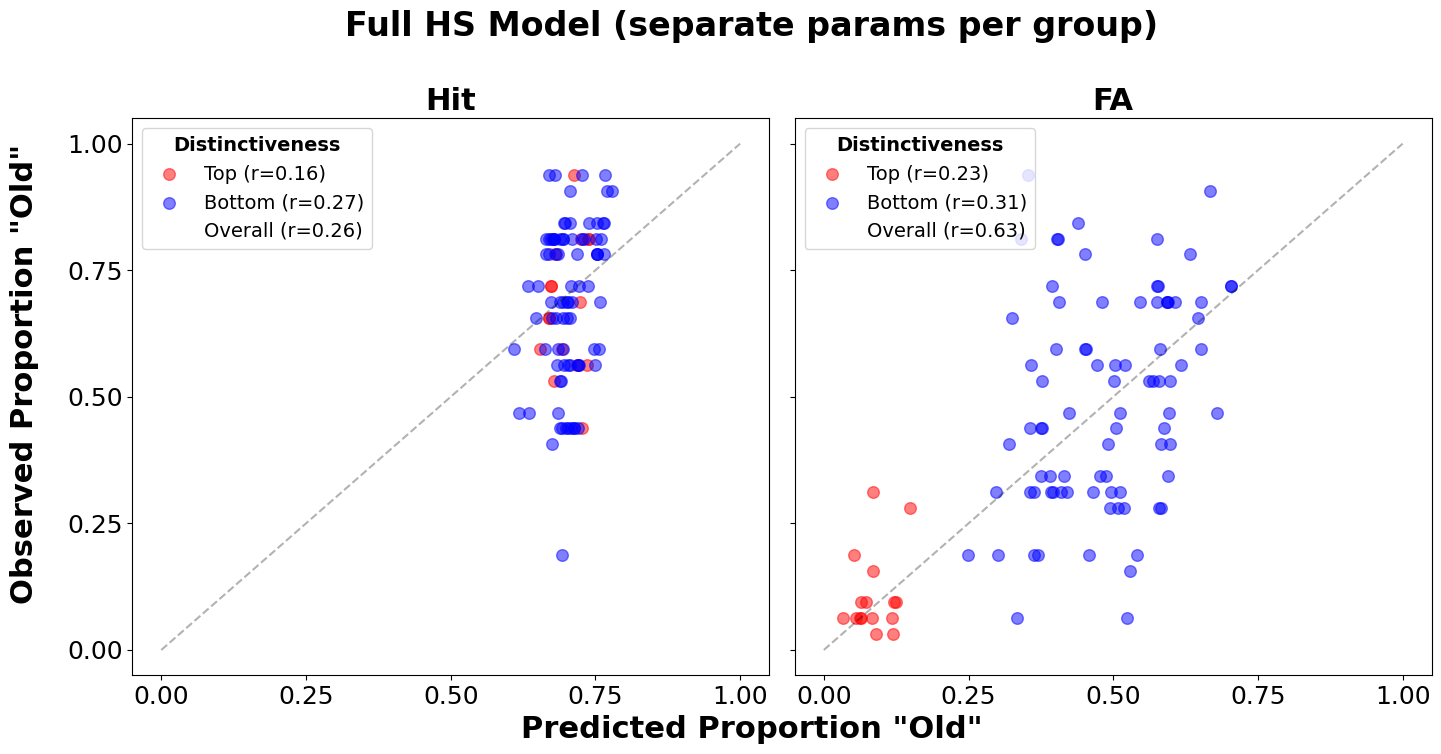

In [78]:
plot_model_fit_by_distinctiveness(df_by_item, 'HS_preds', 'Full HS Model (separate params per group)')

In [79]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'HS_preds', 'Full HS Model')

========== Full HS Model ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.159   0.556
1       Hit        Bottom  0.268   0.014
2       Hit       Overall  0.257   0.010
3        FA           Top  0.225   0.402
4        FA        Bottom  0.308   0.004
5        FA       Overall  0.627  < .001
6   Overall       Overall  0.708  < .001



### HS pooled

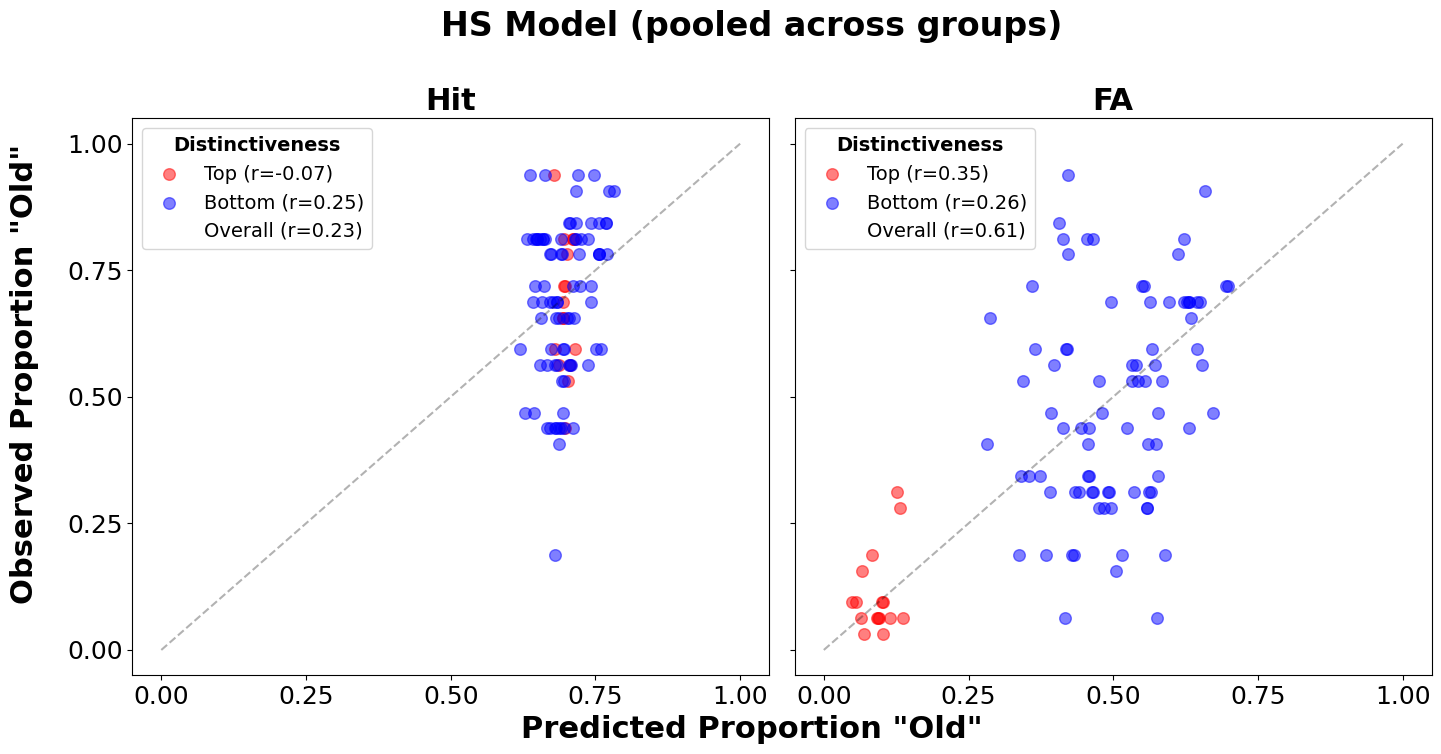

In [80]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

In [81]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

========== HS Model (pooled across groups) ==========
  resp_type distinct_type      r p_value
0       Hit           Top -0.067   0.806
1       Hit        Bottom  0.249   0.022
2       Hit       Overall  0.230   0.021
3        FA           Top  0.349   0.186
4        FA        Bottom  0.257   0.018
5        FA       Overall  0.613  < .001
6   Overall       Overall  0.697  < .001



### Base model

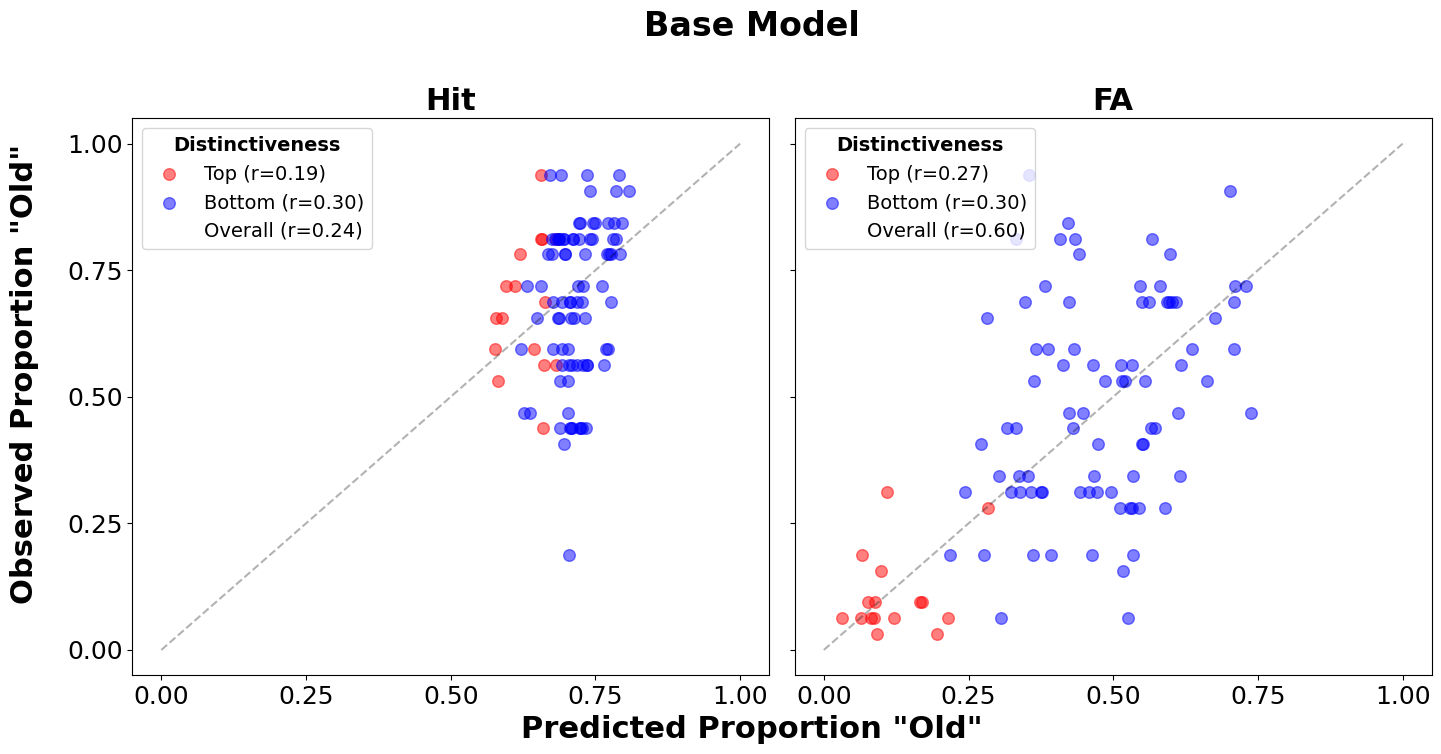

In [82]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

In [83]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

========== Base Model ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.189   0.483
1       Hit        Bottom  0.297   0.006
2       Hit       Overall  0.235   0.018
3        FA           Top  0.266   0.320
4        FA        Bottom  0.304   0.005
5        FA       Overall  0.603  < .001
6   Overall       Overall  0.695  < .001



## H vs FA

In [84]:
def plot_hit_fa_cross_correlations(df_by_item, pred_col, model_label):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True, sharex=True)

    distinct_groups = {'Top': 'High', 'Bottom': 'Low'}
    colors = ['red', 'blue']

    # font sizes
    fs = 22
    fs_axes = 18
    fs_legend = 15

    lims = [-0.05, 1.05]

    # For overall correlations (per subplot)
    x_all_0, y_all_0 = [], []
    x_all_1, y_all_1 = [], []

    for color, distinct in zip(colors, distinct_groups):

        dist_name = distinct_groups[distinct]

        # ---------- Set A (left column) ----------
        ax_left = axes[0]

        x = df_by_item.loc[
            (df_by_item['distinct_type'] == distinct) &
            (df_by_item['group'] == 'Group2') &
            (df_by_item['resp_type'] == 'FA'),
            pred_col
        ].reset_index(drop=True)

        y = df_by_item.loc[
            (df_by_item['distinct_type'] == distinct) &
            (df_by_item['group'] == 'Group1') &
            (df_by_item['resp_type'] == 'Hit'),
            pred_col
        ].reset_index(drop=True)

        mask = ~(x.isna() | y.isna())
        r = x[mask].corr(y[mask])

        ax_left.scatter(
            x, y, alpha=0.5, edgecolor="k", color=color, s=100,
            label=f"{dist_name} (r = {r:.3f})"
        )

        # ---------- Set B (right column) ----------
        ax_right = axes[1]

        x_rev = df_by_item.loc[
            (df_by_item['distinct_type'] == distinct) &
            (df_by_item['group'] == 'Group1') &
            (df_by_item['resp_type'] == 'FA'),
            pred_col
        ].reset_index(drop=True)

        y_rev = df_by_item.loc[
            (df_by_item['distinct_type'] == distinct) &
            (df_by_item['group'] == 'Group2') &
            (df_by_item['resp_type'] == 'Hit'),
            pred_col
        ].reset_index(drop=True)

        mask_rev = ~(x_rev.isna() | y_rev.isna())
        r_rev = x_rev[mask_rev].corr(y_rev[mask_rev])

        ax_right.scatter(
            x_rev, y_rev, alpha=0.5, edgecolor="k", color=color, s=100,
            label=f"{dist_name} (r = {r_rev:.3f})"
        )

        # accumulate for overall correlations
        x_all_0.append(x)
        y_all_0.append(y)
        x_all_1.append(x_rev)
        y_all_1.append(y_rev)

    # ---------- Overall correlations ----------
    x0 = pd.concat(x_all_0, ignore_index=True)
    y0 = pd.concat(y_all_0, ignore_index=True)
    x1 = pd.concat(x_all_1, ignore_index=True)
    y1 = pd.concat(y_all_1, ignore_index=True)

    mask0 = ~(x0.isna() | y0.isna())
    mask1 = ~(x1.isna() | y1.isna())

    r0 = x0[mask0].corr(y0[mask0])
    r1 = x1[mask1].corr(y1[mask1])

    overall_handle_0 = Line2D([], [], linestyle='None',
                              label=f"Overall (r = {r0:.3f})")
    overall_handle_1 = Line2D([], [], linestyle='None',
                              label=f"Overall (r = {r1:.3f})")

    # ---------- Formatting ----------
    for col in range(2):
        ax = axes[col]
        ax.plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_xticks(np.arange(0, 1.1, 0.25))
        ax.set_yticks(np.arange(0, 1.1, 0.25))
        ax.tick_params(axis='both', labelsize=fs_axes)

    # titles
    axes[0].set_title('Set A', fontsize=fs, fontweight='bold')
    axes[1].set_title('Set B', fontsize=fs, fontweight='bold')

    # legends
    handles0, labels0 = axes[0].get_legend_handles_labels()
    axes[0].legend(
        handles0 + [overall_handle_0],
        labels0 + [overall_handle_0.get_label()],
        title="Distinctiveness",
        fontsize=fs_legend,
        title_fontsize=fs_legend,
        loc='lower right'
    )
    axes[0].get_legend().get_title().set_fontweight('bold')

    handles1, labels1 = axes[1].get_legend_handles_labels()
    axes[1].legend(
        handles1 + [overall_handle_1],
        labels1 + [overall_handle_1.get_label()],
        title="Distinctiveness",
        fontsize=fs_legend,
        title_fontsize=fs_legend,
        loc='lower right'
    )
    axes[1].get_legend().get_title().set_fontweight('bold')

    # labels
    axes[0].set_ylabel('Hit group 1', fontweight='bold', fontsize=fs)
    axes[0].set_xlabel('FA group 2', fontweight='bold', fontsize=fs)

    axes[1].set_ylabel('Hit group 2', fontweight='bold', fontsize=fs)
    axes[1].set_xlabel('FA group 1', fontweight='bold', fontsize=fs)

    fig.suptitle(f'{model_label} predictions', fontsize=fs + 2, fontweight='bold')

    plt.tight_layout()
    plt.show()

### HS model

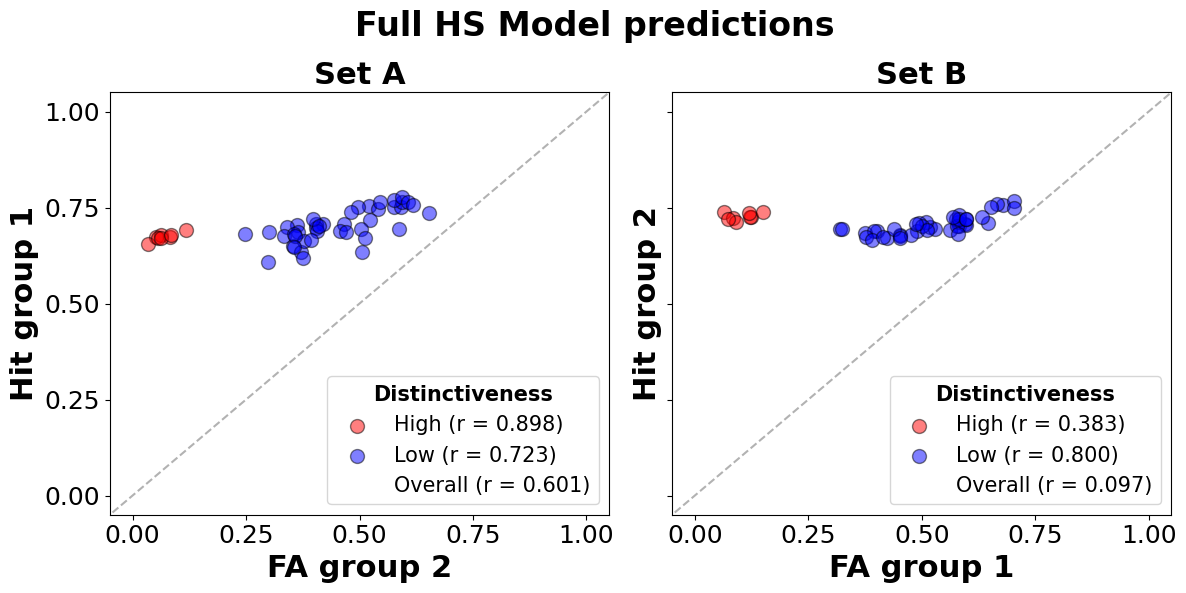

In [85]:
plot_hit_fa_cross_correlations(df_by_item, 'HS_preds', 'Full HS Model')

In [86]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='HS_preds')

Column: HS_preds

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.90, p = 0.002, n = 8
  Bottom: r = 0.72, p = 0.000, n = 42
  Overall: r = 0.60, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.38, p = 0.349, n = 8
  Bottom: r = 0.80, p = 0.000, n = 42
  Overall: r = 0.10, p = 0.504, n = 50


### HS pooled

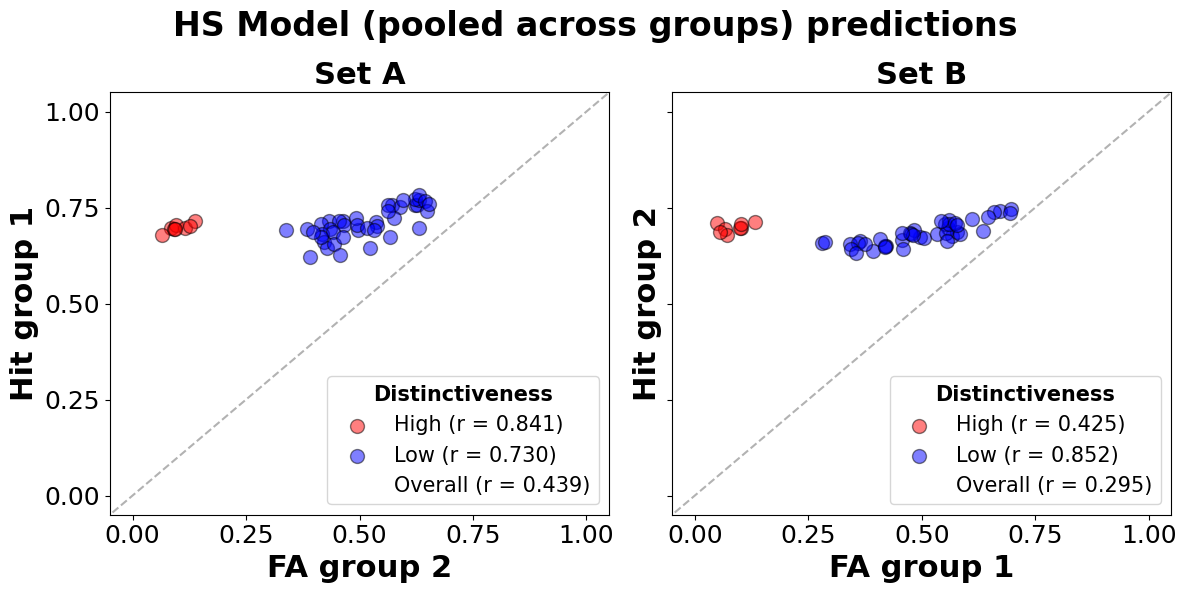

In [87]:
plot_hit_fa_cross_correlations(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

In [88]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='HS_pooled_groups_preds')

Column: HS_pooled_groups_preds

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.84, p = 0.009, n = 8
  Bottom: r = 0.73, p = 0.000, n = 42
  Overall: r = 0.44, p = 0.001, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.43, p = 0.294, n = 8
  Bottom: r = 0.85, p = 0.000, n = 42
  Overall: r = 0.30, p = 0.037, n = 50


### Base model

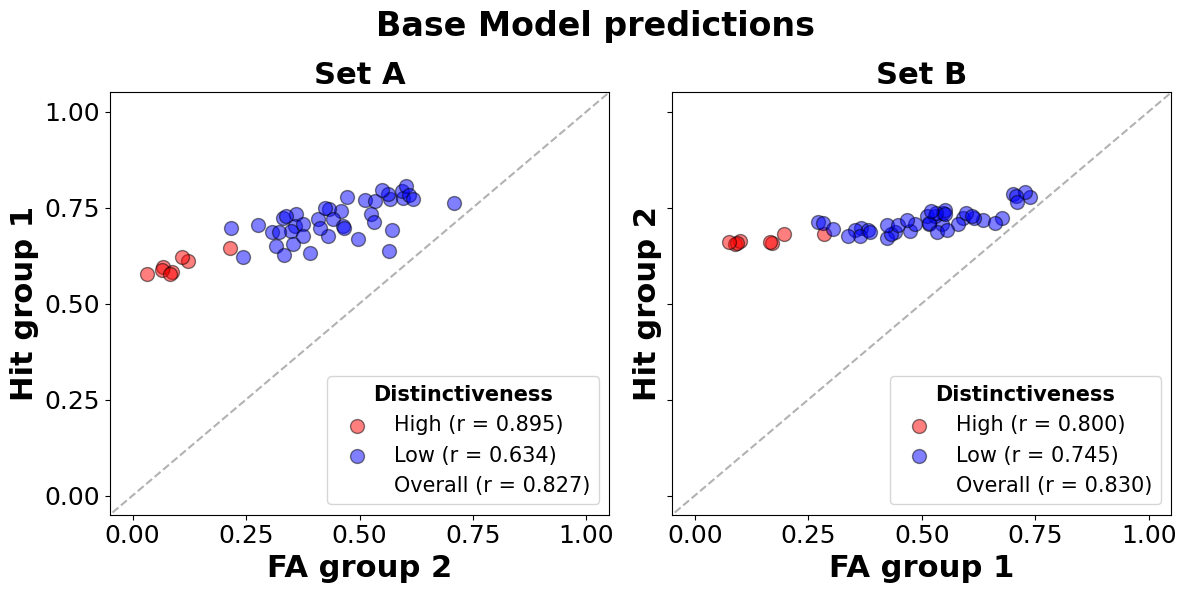

In [89]:
plot_hit_fa_cross_correlations(df_by_item, 'Base_preds', 'Base Model')

In [90]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='Base_preds')

Column: Base_preds

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.90, p = 0.003, n = 8
  Bottom: r = 0.63, p = 0.000, n = 42
  Overall: r = 0.83, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.80, p = 0.017, n = 8
  Bottom: r = 0.75, p = 0.000, n = 42
  Overall: r = 0.83, p = 0.000, n = 50


## Aggregated

In [91]:
# Aggregated plot of model predictions and observed data, by response type and distinctiveness
def plot_model_summary(df_by_item, by_set=False, fs=20, fs_axes=16, fs_leg=13):
    distinct_levels = ["Bottom", "Top"]
    resp_levels = ["Hit", "FA"]

    color_map = {"Bottom": "blue", "Top": "red"}
    distinct_label_map = {"Bottom": "Low", "Top": "High"}

    x_pos = np.array([0])
    bar_width = 0.35
    offsets = {"Bottom": -bar_width / 2, "Top": bar_width / 2}
    model_offset = {"hs": -0.09, "pooled": 0.0, "base": 0.09}
    marker_map = {"hs": ("s", "Full model"), "pooled": ("^", "Pooled model"), "base": ("o", "Base model")}

    panel_w, panel_h = 7, 5  # size of a single subplot, used for both layouts

    # -------- summary stats --------
    group_cols = ["resp_type", "distinct_type"] + (["group"] if by_set else [])
    summary = (
        df_by_item
        .groupby(group_cols, observed=False)
        .agg(
            mean_prop=("prop_yes", "mean"),
            mean_hs=("HS_preds", "mean"),
            mean_pooled=("HS_pooled_groups_preds", "mean"),
            mean_base=("Base_preds", "mean"),
            n=("prop_yes", "size"),
            sd=("prop_yes", "std")
        )
        .reset_index()
    )
    summary["se"] = summary["sd"] / np.sqrt(summary["n"])
    summary["ci95"] = summary["se"] * stats.t.ppf(0.975, summary["n"] - 1)

    # -------- panel layout --------
    if by_set:
        sets = {"Set A": {"Hit": "Group1", "FA": "Group2"},
                "Set B": {"Hit": "Group2", "FA": "Group1"}}
        nrows, ncols = 2, 2
        fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows), sharey=True)
        panels = [(r, c, set_name, resp, group_map[resp])
                  for r, (set_name, group_map) in enumerate(sets.items())
                  for c, resp in enumerate(resp_levels)]
    else:
        nrows, ncols = 1, 2
        fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows), sharey=True)
        axes = axes.reshape(1, -1)
        panels = [(0, c, None, resp, None) for c, resp in enumerate(resp_levels)]

    # -------- draw each panel --------
    for row_idx, col_idx, set_name, resp, group in panels:
        ax = axes[row_idx, col_idx]

        for distinct in distinct_levels:
            color = color_map[distinct]
            bar_offset = offsets[distinct]

            filt = (
                (summary["resp_type"] == resp) &
                (summary["distinct_type"] == distinct) &
                (True if not by_set else summary["group"] == group)
            )
            sub = summary[filt]

            mean_val = sub["mean_prop"].iloc[0]
            ci_val = sub["ci95"].iloc[0]
            model_vals = {m: sub[f"mean_{m}"].iloc[0] for m in marker_map}

            ax.bar(x_pos + bar_offset, [mean_val], width=bar_width, color=color, alpha=0.5,
                   label=f"{distinct_label_map[distinct]} - Observed")
            ax.errorbar(x_pos + bar_offset, [mean_val], yerr=[ci_val], fmt="none",
                        ecolor=color, elinewidth=2, capsize=6, capthick=2)

            for m, (marker, label) in marker_map.items():
                ax.scatter(x_pos + bar_offset + model_offset[m], [model_vals[m]],
                           marker=marker, s=150, color=color,
                           edgecolors="k", linewidths=0.8, zorder=5,
                           label=f"{distinct_label_map[distinct]} - {label}")

        title = f"{set_name} — {resp}" if by_set else resp
        ax.set_title(title, fontsize=fs, fontweight="bold")
        ax.set_xticks([])
        ax.set_xlim(-0.6, 0.6)
        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks(np.arange(0, 1.1, 0.25))
        ax.tick_params(axis="both", labelsize=fs_axes)
        ax.text(0.05, 0.95, "Error bars = observed 95% CI", transform=ax.transAxes,
                fontsize=12, color="gray")

    # -------- shared legend --------
    legend_elements = [
        Patch(facecolor="blue", alpha=0.5, label="Low - Observed"),
        Patch(facecolor="red", alpha=0.5, label="High - Observed"),
        Line2D([0], [0], marker="None", color="w", markersize=10, label=""),  # spacer
        Line2D([0], [0], marker="s", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Full model"),
        Line2D([0], [0], marker="^", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Pooled model"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
               markeredgecolor="k", markersize=10, label="Base model"),
    ]
    leg = fig.legend(handles=legend_elements, loc="center right",
                      bbox_to_anchor=(1.17, 0.5),
                      fontsize=fs_leg, frameon=True,
                      title="Distinctiveness",
                      title_fontsize=fs_leg)
    leg.get_title().set_fontweight('bold')

    fig.text(-0.02, 0.5, 'Proportion "Old"', va="center",
              rotation="vertical", fontsize=fs, fontweight="bold")

    plt.tight_layout()
    plt.show()

### For H & FA

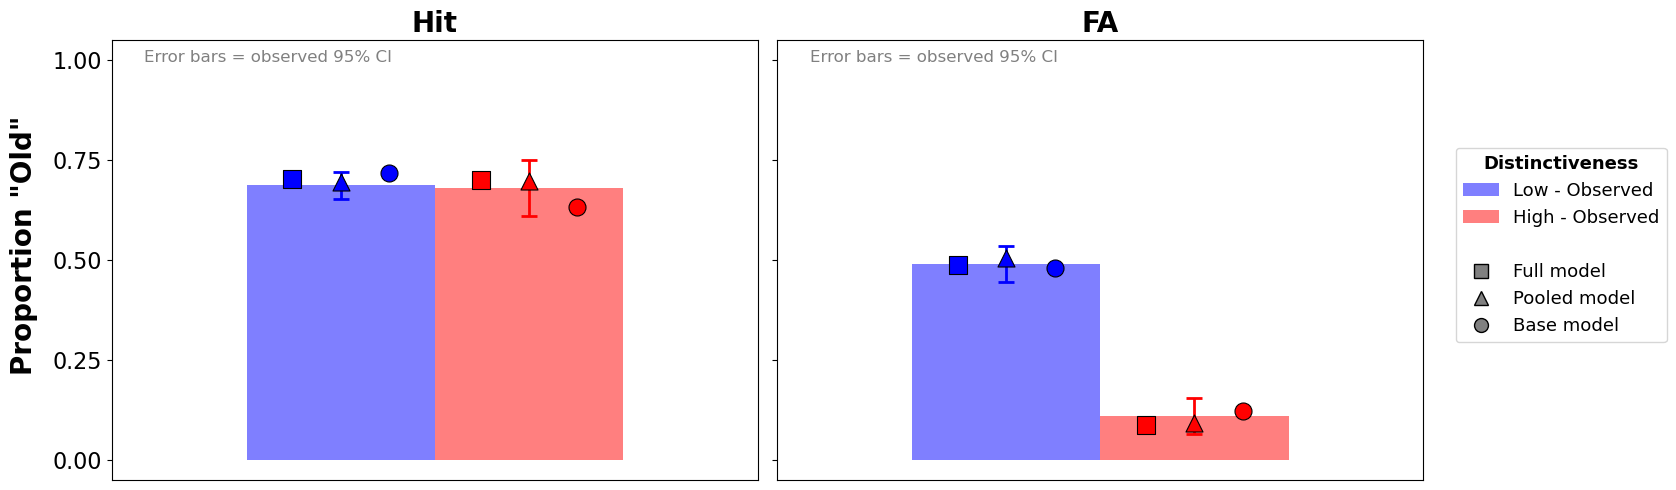

In [92]:
plot_model_summary(df_by_item, by_set=False) 

### For H & FA * Set A & B

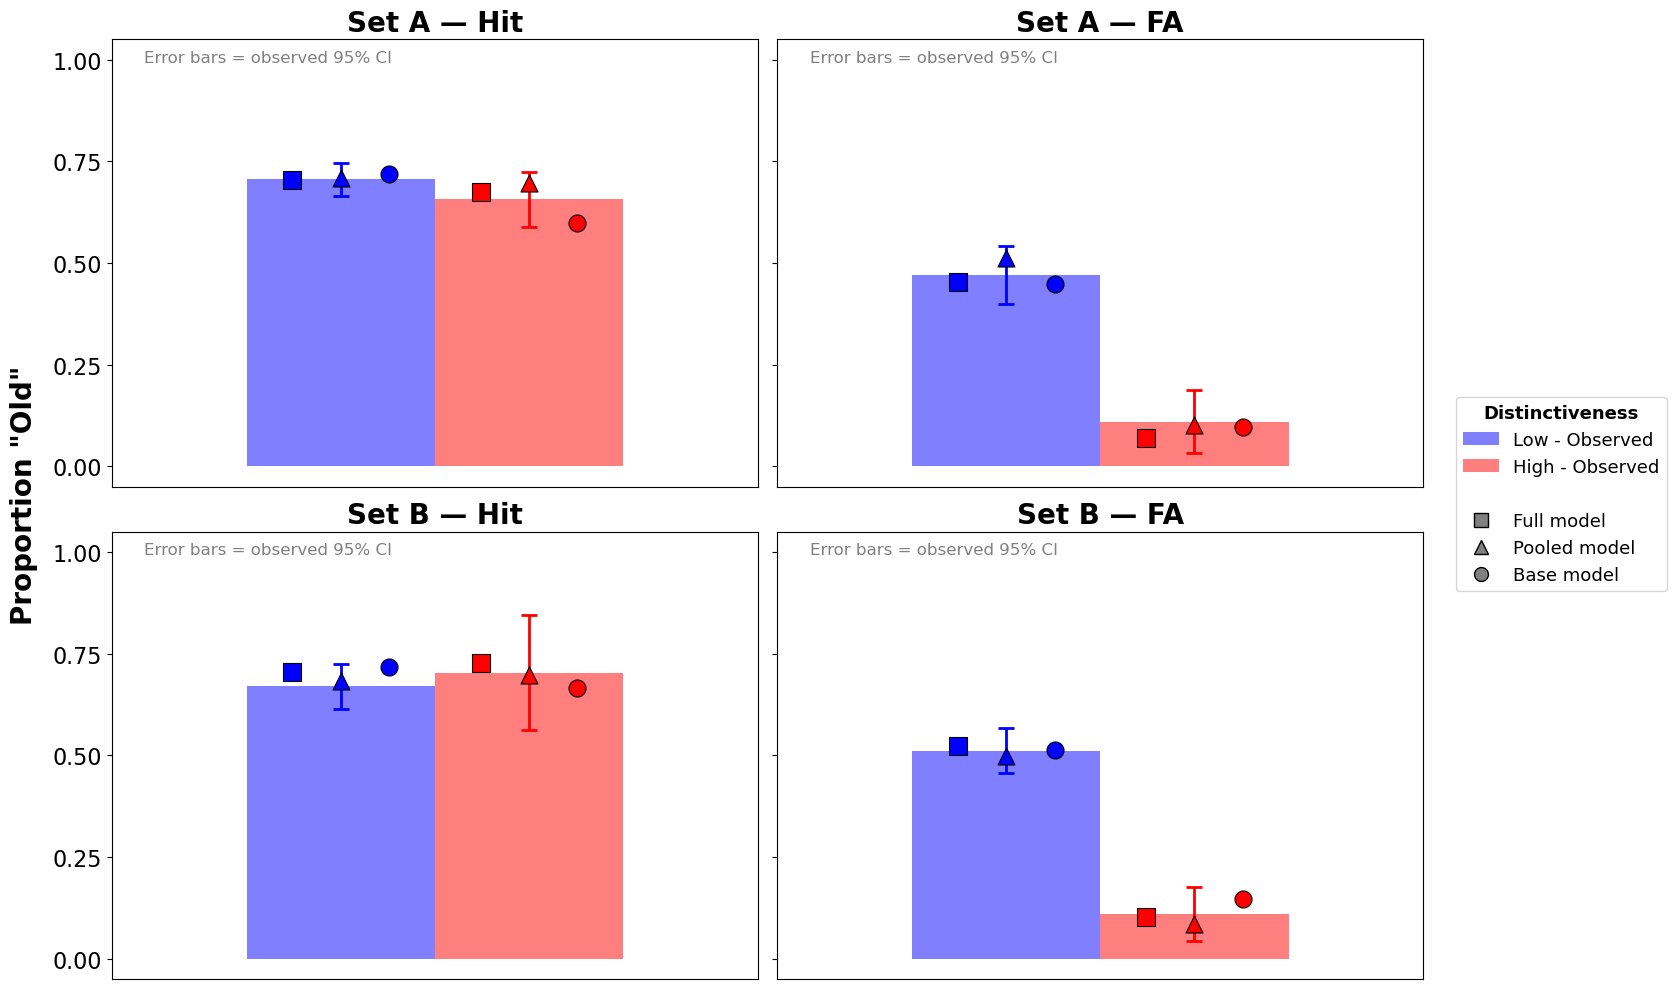

In [93]:
plot_model_summary(df_by_item, by_set=True)

# Model Comparison

In [94]:
n_pooled = len(filtered_data_test)

# Pooled: k=4, fit jointly
nll_pooled = optimization_result['HS_pooled_groups_model'].fun
k_pooled = 4

# HS full: two independent group fits, params NOT shared → k = 4+4 = 8
nll_full = sum(
    optimization_result['HS_model'][g].fun for g in ['Group1', 'Group2']
)
k_full = 8

# Base: two independent group fits → k = 2+2 = 4
nll_base = sum(
    optimization_result['Base_model'][g].fun for g in ['Group1', 'Group2']
)
k_base = 4

def aic(k, nll): return 2 * k + 2 * nll
def bic(k, n, nll): return k * np.log(n) + 2 * nll

results_aic_bic = [{
    'NLL_HS': round(nll_full, 3), 'NLL_Pooled': round(nll_pooled, 3), 'NLL_Base': round(nll_base, 3),
    'AIC_HS': round(aic(k_full, nll_full), 3), 'AIC_Pooled': round(aic(k_pooled, nll_pooled), 3), 'AIC_Base': round(aic(k_base, nll_base), 3),
    'BIC_HS': round(bic(k_full, n_pooled, nll_full), 3), 'BIC_Pooled': round(bic(k_pooled, n_pooled, nll_pooled), 3), 'BIC_Base': round(bic(k_base, n_pooled, nll_base), 3),
}]

df_aic_bic = pd.DataFrame(results_aic_bic)
print(df_aic_bic.to_string(index=False))

  NLL_HS  NLL_Pooled  NLL_Base   AIC_HS  AIC_Pooled  AIC_Base   BIC_HS  BIC_Pooled  BIC_Base
1341.114    1345.882  1348.791 2698.227    2699.765  2705.581 2743.797     2722.55  2728.366


# Save data

In [95]:
# Save only the variables you actually need
variables_to_save = {
    # all IDs
    #'credited_IDs': credited_IDs,
    # Split-half lists
    'split_half_hits_within_dict' : sh_corrs_hits,
    'split_half_fa_within_dict' : sh_corrs_fa,

    # Aggregated by item
    'df_by_item': df_by_item,
    'df_by_item_wide': df_by_item_wide,
    
    # Distance matrices
    'dist_mat_gr1': dist_mat_gr1,
    'dist_mat_gr2': dist_mat_gr2,
    
    # Distinctiveness dictionary
    'distinctiveness_image_id': distinctiveness_image_id,
    
    # Optimizers for 
    'optimization_result': optimization_result,
    
    # All data (test and memory phases)
    'filtered_data_test': filtered_data_test,
    'filtered_data_memory': filtered_data_memory,

    # Add other variables you want to keep
}

with open("Exp1_1rep_analysis.pkl", "wb") as f:
    dill.dump(variables_to_save, f)

## Model parameters & comparison

In [103]:
# Model comparison summary: PARAMETERS (descriptive) + MODEL COMPARISON (valid AIC/BIC)
lines = []

def get_n(group):
    return len(filtered_data_test.loc[filtered_data_test["group"] == group])

def get_n_pooled():
    return len(filtered_data_test)

# ══════════════════════════════════════════════════════════════════════════
# PART 1 — FITTED PARAMETERS (per group; NLL shown for reference
# only, not to be compared across models here — see Part 2 for that)
# ══════════════════════════════════════════════════════════════════════════

lines.append("PART 1: FITTED PARAMETERS")
lines.append("=" * 80)

lines.append("")
lines.append("FULL MODEL (Hybrid-Similarity Model)")
lines.append("Parameters: c, alpha, beta, k (fit separately per group)")
lines.append("-" * 80)
lines.append(f"{'Group':<10} {'c':>8} {'alpha':>8} {'beta':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
for group, result in optimization_result['HS_model'].items():
    c, alpha, beta, k = [round(x, 3) for x in result.x]
    nll = round(result.fun, 3)
    lines.append(f"{group:<10} {c:>8} {alpha:>8} {beta:>8} {k:>8} {nll:>10}")

lines.append("")
lines.append("POOLED MODEL (Hybrid-Similarity Model, parameters shared across groups)")
lines.append("Parameters: c, alpha, beta, k (fit jointly on Group1 + Group2)")
lines.append("-" * 80)
lines.append(f"{'c':>8} {'alpha':>8} {'beta':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
result = optimization_result['HS_pooled_groups_model']
c, alpha, beta, k = [round(x, 3) for x in result.x]
nll = round(result.fun, 3)
lines.append(f"{c:>8} {alpha:>8} {beta:>8} {k:>8} {nll:>10}")

lines.append("")
lines.append("BASE MODEL (Reduced: alpha=0, beta=0 fixed)")
lines.append("Parameters: c, k")
lines.append("-" * 80)
lines.append(f"{'Group':<10} {'c':>8} {'k':>8} {'NLL':>10}")
lines.append("-" * 80)
for group, result in optimization_result['Base_model'].items():
    c, k = [round(x, 3) for x in result.x]
    nll = round(result.fun, 3)
    lines.append(f"{group:<10} {c:>8} {k:>8} {nll:>10}")

# ══════════════════════════════════════════════════════════════════════════
# PART 2 — MODEL COMPARISON (AIC/BIC), all on n_pooled
#
# AIC/BIC are only valid to compare across models fit on the SAME data.
# Pooled is fit jointly on both groups (n_pooled, k=4). HS and Base are fit
# per-group with independent parameters, so their combined description of
# the n_pooled dataset uses k = 4+4=8 (HS) or 2+2=4 (Base), with NLL summed
# across the two group fits.
# ══════════════════════════════════════════════════════════════════════════

lines.append("")
lines.append("")
lines.append("PART 2: MODEL COMPARISON (AIC / BIC, n = n_pooled)")
lines.append("=" * 80)
lines.append(f"{'Model':<10} {'k':>4} {'NLL':>10} {'AIC':>10} {'BIC':>10}")
lines.append("-" * 80)

comparison_rows = []

n_pooled = get_n_pooled()

# Pooled: single joint fit, k=4
nll_pooled = optimization_result['HS_pooled_groups_model'].fun
k_pooled = 4

# HS full: two independent group fits, not shared -> k = 8
nll_full = sum(
    optimization_result['HS_model'][g].fun for g in ['Group1', 'Group2']
)
k_full = 8

# Base: two independent group fits -> k = 4
nll_base = sum(
    optimization_result['Base_model'][g].fun for g in ['Group1', 'Group2']
)
k_base = 4

def aic(k, nll):
    return 2 * k + 2 * nll

def bic(k, n, nll):
    return k * np.log(n) + 2 * nll

for model_name, k, nll in [
    ('Full', k_full, nll_full),
    ('Pooled', k_pooled, nll_pooled),
    ('Base', k_base, nll_base),
]:
    a = round(aic(k, nll), 3)
    b = round(bic(k, n_pooled, nll), 3)
    nll_r = round(nll, 3)
    lines.append(f"{model_name:<10} {k:>4} {nll_r:>10} {a:>10} {b:>10}")
    comparison_rows.append({
        'Model': model_name, 'k': k,
        'n': n_pooled, 'NLL': nll_r, 'AIC': a, 'BIC': b,
    })

df_comparison = pd.DataFrame(comparison_rows)

# ── Write to file ─────────────────────────────────────────────────────────────
output_path = "model_parameters_1cond_1rep.txt"
with open(output_path, "w") as f:
    f.write("\n".join(lines))

print(f"Saved to {output_path}")
print("\n".join(lines))

Saved to model_parameters_1cond_1rep.txt
PART 1: FITTED PARAMETERS

FULL MODEL (Hybrid-Similarity Model)
Parameters: c, alpha, beta, k (fit separately per group)
--------------------------------------------------------------------------------
Group             c    alpha     beta        k        NLL
--------------------------------------------------------------------------------
Group1        0.627    0.195    0.123    1.268    917.654
Group2        0.875    0.155    0.091    0.745    423.459

POOLED MODEL (Hybrid-Similarity Model, parameters shared across groups)
Parameters: c, alpha, beta, k (fit jointly on Group1 + Group2)
--------------------------------------------------------------------------------
       c    alpha     beta        k        NLL
--------------------------------------------------------------------------------
   0.692    0.192    0.119    1.077   1345.882

BASE MODEL (Reduced: alpha=0, beta=0 fixed)
Parameters: c, k
------------------------------------------------

# Data for Nosofsky

In [97]:
# ---- shared maps ----
group_map       = {"Group1": 1, "Group2": 2}
item_type_map   = {"Foil": 0, "Target": 1}
distinct_map    = {"Bottom": 0, "Top": 1}
resp_type_map   = {"FA": 0, "Hit": 1, "CR": 2, "Miss": 3}
old_new_map     = {"a": 0, "l": 1}
task_map        = {"memory_phase": 0, "test_phase": 1}

In [98]:
def recode_common(df):
    df = df.copy()
    if "group" in df:          df["group"] = df["group"].map(group_map).astype(int)
    if "item_type" in df:      df["item_type"] = df["item_type"].map(item_type_map).astype("Int64")
    if "distinct_type" in df:  df["distinct_type"] = df["distinct_type"].map(distinct_map).astype(int)
    if "subject_id" in df:     df["subject_id"] = df["subject_id"].astype(int)
    if "good_subj" in df:      df["good_subj"] = df["good_subj"].astype(int)
    return df

In [99]:
# ---- df_by_item ----
df_by_item_nosofsky = recode_common(df_by_item)
df_by_item_nosofsky["resp_type"] = df_by_item_nosofsky["resp_type"].map(resp_type_map).astype(int)
by_item_cols = ["image_id", "group", "n_subj", "n_yes", "item_type",
                "distinct_rating", "distinct_type", "prop_yes", "resp_type",
                "HS_preds", "HS_pooled_groups_preds", "Base_preds"]
df_by_item_nosofsky = df_by_item_nosofsky[by_item_cols]

# ---- data_test / data_memory: recode first ----
data_test_nosofsky = recode_common(data_test)
data_test_nosofsky["response"] = data_test_nosofsky["response"].map(old_new_map).astype(int)
data_test_nosofsky["correct_response"] = data_test_nosofsky["correct_response"].map(old_new_map).astype(int)
data_test_nosofsky["cor_ans"] = data_test_nosofsky["cor_ans"].astype(int)
data_test_nosofsky["task"] = data_test_nosofsky["task"].map(task_map).astype(int)
data_test_nosofsky["condition"] = 0 # only 1 rep

data_memory_nosofsky = recode_common(data_memory)
data_memory_nosofsky["task"] = data_memory_nosofsky["task"].map(task_map).astype(int)
data_memory_nosofsky["item_type"] = 1  # study phase only shows targets
data_memory_nosofsky["condition"] = 0 # only 1 rep

# ---- 1) renumber subject_id 1..N, consistent across both datasets ----
all_subjects = sorted(set(data_test_nosofsky["subject_id"]) |
                       set(data_memory_nosofsky["subject_id"]))
subject_map = {old: new for new, old in enumerate(all_subjects, start=1000)}

data_test_nosofsky["subject_id"] = data_test_nosofsky["subject_id"].map(subject_map)
data_memory_nosofsky["subject_id"] = data_memory_nosofsky["subject_id"].map(subject_map)

# ---- 2) renumber trial_index 1..n_trials within each subject, preserving original order ----
def renumber_trials(df):
    df = df.sort_values(["subject_id", "trial_index"]).copy()
    df["trial_index"] = df.groupby("subject_id").cumcount() + 1
    return df

data_test_nosofsky = renumber_trials(data_test_nosofsky)
data_memory_nosofsky = renumber_trials(data_memory_nosofsky)

# ---- column selection (description order; model preds dropped here, kept only in df_by_item) ----
test_cols = ["trial_index", "subject_id", "group", "condition", "task", "item_type",
             "response", "correct_response", "cor_ans", "rt", "category", "image_id",
             "distinct_rating", "distinct_type", "good_subj"]
data_test_nosofsky = data_test_nosofsky[test_cols]

memory_cols = ["trial_index", "subject_id", "group", "condition", "task", "item_type",
               "category", "image_id", "distinct_rating", "distinct_type", "good_subj"]
data_memory_nosofsky = data_memory_nosofsky[memory_cols]

In [100]:
# ---- sanity checks ----
for name, df in [("df_by_item_nosofsky", df_by_item_nosofsky),
                  ("data_test_nosofsky", data_test_nosofsky),
                  ("data_memory_nosofsky", data_memory_nosofsky)]:
    bad = df.select_dtypes(include=["object", "category", "bool", "string"]).columns.tolist()
    print(name, "non-numeric columns remaining:", bad, "| shape:", df.shape)

print("subject_id range (test):", data_test_nosofsky["subject_id"].min(),
      data_test_nosofsky["subject_id"].max())
print("subject_id range (memory):", data_memory_nosofsky["subject_id"].min(),
      data_memory_nosofsky["subject_id"].max())
print("trial_index range (test):", data_test_nosofsky.groupby("subject_id")["trial_index"].max().describe())
print("trial_index range (memory):", data_memory_nosofsky.groupby("subject_id")["trial_index"].max().describe())

df_by_item_nosofsky non-numeric columns remaining: [] | shape: (200, 12)
data_test_nosofsky non-numeric columns remaining: [] | shape: (4300, 15)
data_memory_nosofsky non-numeric columns remaining: [] | shape: (2150, 11)
subject_id range (test): 1000 1042
subject_id range (memory): 1000 1042
trial_index range (test): count     43.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: trial_index, dtype: float64
trial_index range (memory): count    43.0
mean     50.0
std       0.0
min      50.0
25%      50.0
50%      50.0
75%      50.0
max      50.0
Name: trial_index, dtype: float64


In [ ]:
# # ---- save ----
# df_by_item_nosofsky.to_csv("data_by_item_1cond_1rep.txt", sep=" ", index=False)
# data_test_nosofsky.to_csv("test_data_1cond_1rep.txt", sep=" ", index=False)
# data_memory_nosofsky.to_csv("memory_data_1cond_1rep.txt", sep=" ", index=False)